# Brain Tumor MRI — Unified 3-Model Benchmark
## VGG16-BN · DenseNet121 · ResNet50 | Kaggle 2×T4 | Single notebook, top-to-bottom

Trains and evaluates **all three backbones sequentially** under one shared protocol, then runs the
full comparison, statistics and export stage.

**Artifact contract for the XAI notebook** — everything it needs is written here:

| File | Contents |
|---|---|
| `models/vgg16_best.pth` | self-describing checkpoint: weights **+** `backbone_name`, `in_features`, `num_classes`, `class_names`, `img_size`, `eval_choice`, metrics |
| `models/densenet121_best.pth` | same |
| `models/resnet50_best.pth` | same |
| `models/best_overall_model.pth` | copy of the designated model (see `BEST_MODEL_OVERRIDE`) |
| `models/{key}_metrics.json`, `_preds.npz`, `_probs.npz`, `_ci.npz`, `_calibration.npz` | per-model artifacts |
| `figures/` | ROC · PR · calibration · confusion matrices · per-class heatmap · per-model history & reliability (`.png` @300 dpi **and** `.pdf`) |
| `tables/` | benchmark · CI · McNemar (`.csv` + `.md` + `.tex`) |
| `models/manifest.json` | index of every file written |

**Protocol.** 85/15 stratified split of `Training/` (same seed → bit-identical
split), same held-out `Testing/` set, same augmentations, same two-phase protocol (head-only → full
fine-tune), same loss, same hyperparameters, SWA on VGG16-BN only, TTA ×5, 1000-sample bootstrap CIs.

---
### Implementation notes
These notes document implementation details that affect correctness. They do not change the methodology or any hyperparameter.

| ID | Issue | Implementation |
|---|---|---|
| **B1** | `ReduceLROnPlateau` and `SequentialLR(warmup→cosine)` both wrote `param_group['lr']`. The cosine's recursive `get_lr()` assumes it owns that field, so the schedule was corrupted — visible in the original logs as `6.44e-5 → 2.94e-5` mid-cosine. | plateau scheduler removed; warmup→cosine only |
| **B2** | `torch.autocast` state is **thread-local**, and `DataParallel` runs replicas in side threads — so autocast never reached the model. **AMP was a silent no-op; everything trained in FP32.** | autocast moved *inside* `BrainTumorModel.forward`, which does execute in the replica thread |
| **B3** | `WeightedRandomSampler` on perfectly balanced data (1400/class) → uniform weights + `replacement=True` = a bootstrap resample. ~37% of training images unseen each epoch. | `shuffle=True, drop_last=True` |
| **B4** | `requires_grad=False` does **not** freeze BatchNorm. Backbone running stats drifted through "frozen" Phase 1, then `reset_bn` threw them away. | `backbone.eval()` during Phase 1; `reset_bn` is now unnecessary and removed |
| **B5** | Early stopping fired *inside* the SWA window (VGG16 stopped at epoch 28; SWA started at 22 → only 7 checkpoints averaged). SWA and early stopping are mutually exclusive by design. | early stop disabled while `in_swa_phase` |
| **B6** | `update_bn()` ran on the **augmented** train set (flips, jitter, blur, erasing). SWA's BN statistics were estimated on corrupted images and then evaluated on clean ones. | dedicated `bn_loader` using the eval transform |
| **B7** | `FocalLoss` derived `pt = exp(-ce)` from a **class-weighted, label-smoothed** CE, so `pt = p_t^{w_y}` and was capped below 1 by smoothing. The focal term was secretly a function of the class weight. | `pt` computed from a clean `log_softmax` |
| S1–S9 | checkpoint filename collision · off-by-one phase marker · optimizer state in every checkpoint · NaN guard skipping `scaler.update()` · unseeded DataLoader workers · `persistent_workers` always False · dead code · wrong `eval_choice` metadata · CLAHE recomputed every epoch | see inline `[Sn]` comments |

### Knowingly left as-is (design choices)
- **`DataParallel`** rather than DDP: BN statistics are computed per-GPU on the half-batch (32, not 64).
- **SWA's LR anneals *upward*** (`6.3e-6 → 5e-5`) because the cosine `T_max` spans all of Phase 2 and has already decayed past `SWA_LR` by the time SWA starts. Changing this would change the method, so it stays.
- **`timm`'s `vgg16_bn` emits `(B, 4096, 1, 1)`** — it already contains the `pre_logits` ConvMlp and pools to 1×1. So inside `BrainTumorHead`, `AdaptiveAvgPool2d(1)` and `AdaptiveMaxPool2d(1)` are *both the identity* for VGG, and `cat([avg, max])` simply duplicates the same 4096-vector into 8192. DenseNet121 (`1024×7×7`) and ResNet50 (`2048×7×7`) use the head as intended. This is why VGG16-BN reports 138,597,700 trainable parameters. Changing the head would change the architecture, so it stays — but a reviewer will ask, so it is documented here.


## §1.1 Install dependencies

In [1]:
import subprocess
subprocess.run(["pip", "install", "-q", "timm", "opencv-python-headless",
                "statsmodels", "tabulate"], check=False)
import timm, cv2, statsmodels
print("OK")

OK


## §1.2 Imports

In [2]:
import os, sys, json, gc, glob, time, random, shutil, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import cv2
import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from tqdm.auto import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn
from torch.optim.lr_scheduler import CosineAnnealingLR, SequentialLR, LinearLR

from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, auc, cohen_kappa_score, matthews_corrcoef,
    precision_recall_curve, average_precision_score,
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedShuffleSplit
from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar as mcnemar_test_fn

warnings.filterwarnings("ignore")
print("Imports done.")

Imports done.


## §1.3 Device, multi-GPU, global seeding

In [3]:
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS        = torch.cuda.device_count()
USE_MULTI_GPU = N_GPUS > 1

for i in range(N_GPUS):
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"Device: {DEVICE} | GPUs: {N_GPUS} | DataParallel: {USE_MULTI_GPU}")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False


def seed_worker(worker_id):
    """[S5] Forked DataLoader workers get their own RNG state. Without this,
    cudnn.deterministic=True is a false promise: the augmentation stream
    (RandomCrop / Rotation / ColorJitter / Erasing) is not reproducible."""
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s)
    random.seed(s)


LOADER_GEN = torch.Generator()
LOADER_GEN.manual_seed(RANDOM_SEED)

print(f"Global seed set: {RANDOM_SEED} (cudnn deterministic, workers seeded)")

  GPU 0: Tesla T4
  GPU 1: Tesla T4
Device: cuda | GPUs: 2 | DataParallel: True
Global seed set: 42 (cudnn deterministic, workers seeded)


## §2.1 Configuration — every hyperparameter lives here

Values are **identical** to the three source notebooks. Nothing below was tuned or changed.

In [4]:
# ── Data ──────────────────────────────────────────────────────────────
VAL_FRAC     = 0.15          # fraction of Training/ held out for validation
IMG_SIZE     = 224
BATCH_SIZE   = 64
NUM_WORKERS  = 4             # [S6] was 2; the §3.1 cache makes the loader cheap enough for 4
NUM_CLASSES  = 4

# ── Augmentation ──────────────────────────────────────────────────────
MIXUP_ALPHA  = 0.2
CUTMIX_ALPHA = 0.5

# ── Loss ──────────────────────────────────────────────────────────────
FOCAL_GAMMA     = 2.5
LABEL_SMOOTHING = 0.1
GLIOMA_BOOST    = 1.3

# ── Phase 1 — head only ───────────────────────────────────────────────
LR_P1        = 1e-3
EPOCHS_P1    = 12
PATIENCE_P1  = 5
WARMUP_P1    = 3
DROPOUT_RATE = 0.4

# ── Phase 2 — full fine-tune ──────────────────────────────────────────
LR_P2_HEAD     = 1e-4
LR_P2_BACKBONE = 3e-5
EPOCHS_P2      = 30
PATIENCE_P2    = 8
WARMUP_P2      = 3
SWA_START_FRAC = 0.70
SWA_LR         = 5e-5
USE_AMP        = True
PRETRAINED     = True        # timm ImageNet weights

# ── Evaluation ────────────────────────────────────────────────────────
TTA_RUNS       = 5
BOOTSTRAP_RUNS = 1000

# ── Housekeeping ──────────────────────────────────────────────────────
SAVE_GLIOMA_CKPT = True      # extra checkpoint at best glioma recall
GRAD_CLIP_NORM   = 1.0

# [B2] AMP only means anything on CUDA. Derived once, used everywhere.
AMP_ON = USE_AMP and torch.cuda.is_available()

print(f"Config loaded. AMP active: {AMP_ON}")

Config loaded. AMP active: True


## §2.2 Model registry — the *only* place the three runs differ

Everything else in this notebook is shared. Set `RUN_MODELS` to a subset if you need to split the
work across two Kaggle sessions; the comparison stage (§9) transparently reloads any missing
model's artifacts from `/kaggle/input`.

In [5]:
MODELS = [
    {"key": "vgg16",       "backbone": "vgg16_bn",    "display": "VGG16-BN",
     "use_swa": True,  "eval_choice": "swa",  "ckpt": "vgg16_best.pth"},
    {"key": "densenet121", "backbone": "densenet121", "display": "DenseNet121",
     "use_swa": False, "eval_choice": "best", "ckpt": "densenet121_best.pth"},
    {"key": "resnet50",    "backbone": "resnet50",    "display": "ResNet50",
     "use_swa": False, "eval_choice": "best", "ckpt": "resnet50_best.pth"},
]

# [Q5] Staging filter - insurance against the 12h Kaggle cap. Default: all three.
RUN_MODELS = ["vgg16", "densenet121", "resnet50"]

# [Q4] Pin the model the XAI notebook will explain. Deterministic by construction.
# Set to None to fall back to auto-selection by macro-F1, which previously tied
# VGG16 and DenseNet121 at the 4th decimal and broke the tie arbitrarily.
BEST_MODEL_OVERRIDE = "vgg16"

SPEC_BY_KEY = {m["key"]: m for m in MODELS}
assert all(k in SPEC_BY_KEY for k in RUN_MODELS), "RUN_MODELS contains an unknown key"
assert BEST_MODEL_OVERRIDE is None or BEST_MODEL_OVERRIDE in SPEC_BY_KEY

print("Registry:")
for m in MODELS:
    mark = "  <- run" if m["key"] in RUN_MODELS else "  (skip)"
    print(f"  {m['display']:<14} backbone={m['backbone']:<13} "
          f"swa={str(m['use_swa']):<5} -> {m['ckpt']}{mark}")
print(f"\nbest_overall_model.pth <- {BEST_MODEL_OVERRIDE or 'auto (macro-F1)'}")

Registry:
  VGG16-BN       backbone=vgg16_bn      swa=True  -> vgg16_best.pth  <- run
  DenseNet121    backbone=densenet121   swa=False -> densenet121_best.pth  <- run
  ResNet50       backbone=resnet50      swa=False -> resnet50_best.pth  <- run

best_overall_model.pth <- vgg16


## §2.3 Paths

In [6]:
_CANDIDATE_ROOTS = [
    os.environ.get("BT_DATASET_ROOT", ""),                       # local / dev override
    "/kaggle/input/brain-tumor-mri-dataset",
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset",
]
DATASET_ROOT = next((p for p in _CANDIDATE_ROOTS if p and os.path.exists(p)), None)
if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Brain-tumor MRI dataset not found. Add the Kaggle dataset "
        "'masoudnickparvar/brain-tumor-mri-dataset' to this notebook. "
        f"Checked: {[p for p in _CANDIDATE_ROOTS if p]}")

TRAIN_DIR = os.path.join(DATASET_ROOT, "Training")
TEST_DIR  = os.path.join(DATASET_ROOT, "Testing")

OUTPUT_DIR = os.environ.get("BT_OUTPUT_DIR", "/kaggle/working")
MODEL_DIR  = os.path.join(OUTPUT_DIR, "models")
FIG_DIR    = os.path.join(OUTPUT_DIR, "figures")
TAB_DIR    = os.path.join(OUTPUT_DIR, "tables")

# [S9/Q3] The preprocessing cache lives on /kaggle/temp, NOT /kaggle/working: it is a
# build artifact and must not count against the 20 GB output quota.
CACHE_ROOT = os.environ.get("BT_CACHE_DIR", "/kaggle/temp/preproc")

for d in (MODEL_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

print(f"Dataset : {DATASET_ROOT}")
print(f"  Training/ exists: {os.path.exists(TRAIN_DIR)}")
print(f"  Testing/  exists: {os.path.exists(TEST_DIR)}")
print(f"Outputs : {OUTPUT_DIR}")
print(f"Cache   : {CACHE_ROOT}")

Dataset : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
  Training/ exists: True
  Testing/  exists: True
Outputs : /kaggle/working
Cache   : /kaggle/temp/preproc


## §3.1 Preprocessing cache  `[S9]`

`RemoveBlackBorder` and `ApplyCLAHE` are **deterministic** and appear in *all three* transform
pipelines (train / val-test / TTA). In the source notebooks they ran inside `__getitem__` — i.e.
once per image, **per epoch, per worker**. Across 7,200 images × ~42 epochs × 3 models that is on
the order of **900k redundant CLAHE + LAB round-trips**. That, not the GPU, was the bottleneck.

Here they run **once** and the result is written as lossless PNG. Reloading a PNG and calling
`.convert("RGB")` returns a **bit-identical `uint8` array**, so this is a pure speedup with zero
numerical effect. The random transforms then begin at `Resize`.

Images are cached at their **native post-crop resolution** — deliberately *not* pre-resized, because
the three pipelines resize to three different targets (`IMG_SIZE`, `IMG_SIZE+16`, `IMG_SIZE+24`) and
a double resize would change the pixels.

In [7]:
class ApplyCLAHE:
    """CLAHE on the L channel of LAB.

    THREAD-SAFETY [fix]: a cv2.CLAHE object caches internal buffers sized to the
    LAST image it saw. Sharing one instance across threads that pass DIFFERENTLY
    SIZED images is a data race -- one thread reallocates the buffer while another
    is indexing tile ROIs against the old dimensions, which surfaces as
    `matrix.cpp:806 (-215) roi.x + roi.width <= m.cols`.

    The original notebooks never hit this because DataLoader uses worker PROCESSES,
    so every worker owned a private CLAHE. The preprocessing cache uses a thread
    pool, which does not. So this class is now STATELESS: the CLAHE is constructed
    per call (createCLAHE is cheap relative to apply()) and the L plane is made
    contiguous before it crosses into OpenCV.

    Output is numerically identical to the old implementation.
    """
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clip_limit     = clip_limit
        self.tile_grid_size = tile_grid_size

    def __call__(self, pil_img):
        img_np = np.array(pil_img.convert("RGB"))
        lab    = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
        clahe  = cv2.createCLAHE(clipLimit=self.clip_limit,
                                 tileGridSize=self.tile_grid_size)   # per call
        lab[:, :, 0] = clahe.apply(np.ascontiguousarray(lab[:, :, 0]))
        return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))


class RemoveBlackBorder:
    """Crop the black scanner border.

    [fix] PIL's crop box is half-open -- (left, upper, right, lower) EXCLUDES the
    right/lower edge -- so the old box dropped one pixel row and column. More
    importantly it could emit a zero-area image on a pathological input, which then
    blew up inside cv2. Both are guarded now.
    """
    MIN_SIDE = 8          # CLAHE's 8x8 tile grid needs at least this

    def __call__(self, img):
        arr  = np.array(img.convert("L"))
        mask = arr > 15
        rows, cols = np.any(mask, axis=1), np.any(mask, axis=0)
        if not rows.any() or not cols.any():
            return img                                   # all-black: leave alone
        r_min, r_max = np.where(rows)[0][[0, -1]]
        c_min, c_max = np.where(cols)[0][[0, -1]]
        pad  = 4
        h, w = arr.shape
        r_min, r_max = max(0, r_min - pad), min(h - 1, r_max + pad)
        c_min, c_max = max(0, c_min - pad), min(w - 1, c_max + pad)
        # +1: crop's right/lower bounds are exclusive
        box = (int(c_min), int(r_min), int(c_max) + 1, int(r_max) + 1)
        if (box[2] - box[0]) < self.MIN_SIDE or (box[3] - box[1]) < self.MIN_SIDE:
            return img                                   # degenerate: leave alone
        return img.crop(box)


class AddGaussianNoise:
    def __init__(self, mean=0.0, std=0.05):
        self.mean, self.std = mean, std

    def __call__(self, t):
        return torch.clamp(t + torch.randn_like(t) * self.std + self.mean, 0, 1)


# Bump this string if the deterministic ops above ever change -> forces a rebuild.
_CACHE_VERSION = "v2:removeblackborder(pad4,thr15,halfopen)+clahe(clip2.0,tile8x8)"


def _preproc_one(args):
    """Worker. Builds its own transforms -- shares NO mutable state across threads."""
    src, dst = args
    if os.path.exists(dst):
        return 0
    try:
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        # .convert("RGB") up front, matching ImageFolder's default loader exactly:
        # otherwise palette / 16-bit / CMYK sources reach OpenCV in a surprising mode.
        img = Image.open(src).convert("RGB")
        img = RemoveBlackBorder()(img)
        img = ApplyCLAHE()(img)                 # stateless -> thread-safe
        img.save(dst, "PNG", compress_level=1)  # lossless
        return 1
    except Exception as e:
        # Never let one bad file kill a 7,000-image build with an opaque C++ assertion.
        _CACHE_FAILURES.append((src, f"{type(e).__name__}: {e}"))
        return 0


_CACHE_FAILURES = []


def build_preproc_cache(src_root, cache_root, splits=("Training", "Testing")):
    """[S9] Apply the deterministic ops once, write lossless PNGs. Idempotent."""
    stamp = os.path.join(cache_root, ".done")
    if os.path.exists(stamp) and open(stamp).read().strip() == _CACHE_VERSION:
        n = sum(len(f) for _, _, f in os.walk(cache_root))
        print(f"Cache hit: {cache_root} ({n} files) - skipping preprocessing.")
        return cache_root

    jobs = []
    for split in splits:
        split_dir = os.path.join(src_root, split)
        for cls in sorted(os.listdir(split_dir)):
            src_cls = os.path.join(split_dir, cls)
            if not os.path.isdir(src_cls):
                continue
            for fn in sorted(os.listdir(src_cls)):
                dst = os.path.join(cache_root, split, cls,
                                   os.path.splitext(fn)[0] + ".png")
                jobs.append((os.path.join(src_cls, fn), dst))

    print(f"Preprocessing {len(jobs)} images -> {cache_root} ...")
    # Threads, not processes: PIL's and OpenCV's C codecs release the GIL, and a
    # ThreadPoolExecutor needs no pickling of notebook-defined functions (which is
    # fragile under spawn/forkserver start methods).
    n_workers = max(1, min(8, (os.cpu_count() or 2) * 2))
    _CACHE_FAILURES.clear()
    with ThreadPoolExecutor(max_workers=n_workers) as ex:
        written = sum(tqdm(ex.map(_preproc_one, jobs), total=len(jobs), desc="cache"))

    if _CACHE_FAILURES:
        print(f"\n[!!] {len(_CACHE_FAILURES)} image(s) failed to preprocess:")
        for p, err in _CACHE_FAILURES[:10]:
            print(f"     {p}\n       -> {err}")
        if len(_CACHE_FAILURES) > 10:
            print(f"     ... and {len(_CACHE_FAILURES) - 10} more")
        raise RuntimeError(
            f"{len(_CACHE_FAILURES)} image(s) could not be preprocessed. "
            "The cache would be incomplete and the splits would silently shrink, "
            "so this is a hard stop. Inspect the paths above.")

    os.makedirs(cache_root, exist_ok=True)
    with open(stamp, "w") as f:
        f.write(_CACHE_VERSION)
    print(f"Cache built: {written} new, {len(jobs) - written} already present.")
    return cache_root


build_preproc_cache(DATASET_ROOT, CACHE_ROOT)
CACHE_TRAIN = os.path.join(CACHE_ROOT, "Training")
CACHE_TEST  = os.path.join(CACHE_ROOT, "Testing")

Preprocessing 7200 images -> /kaggle/temp/preproc ...


cache:   0%|          | 0/7200 [00:00<?, ?it/s]

Cache built: 7200 new, 0 already present.


## §3.2 Transform pipelines

Identical to the source notebooks, minus the two deterministic ops now handled by the cache.
TTA deliberately excludes horizontal flip (anatomical laterality in brain MRI).

In [8]:
_NORM = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE + 24, IMG_SIZE + 24)),
    transforms.RandomCrop((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomApply([transforms.RandomAffine(degrees=0, shear=5)], p=0.2),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 2.0))], p=0.3),
    transforms.ToTensor(),
    transforms.RandomApply([AddGaussianNoise(0, 0.03)], p=0.3),
    _NORM,
    transforms.RandomErasing(p=0.10, scale=(0.02, 0.08)),
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    _NORM,
])

tta_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE + 16, IMG_SIZE + 16)),
    transforms.RandomCrop((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(5),
    transforms.RandomApply([transforms.RandomAffine(degrees=0, shear=3)], p=0.2),
    transforms.ToTensor(),
    _NORM,
])

print("Transforms ready.")

Transforms ready.


## §3.3 Dataset & stratified split

85% / 15% of `Training/` → train / val, stratified, `random_state=RANDOM_SEED`. The split depends
only on the labels and the seed, so it is **bit-identical to the three source notebooks**.
`Testing/` is never touched during training.

`samples` / `targets` are converted to numpy arrays: Python lists trigger copy-on-write page
duplication in forked DataLoader workers, which is what drove RAM up in the originals.

In [9]:
class TransformedSubset(Dataset):
    """Applies `transform` to the samples of `base` selected by `indices`."""

    def __init__(self, base, indices, transform):
        self.base      = base
        self.indices   = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        path, label = self.base.samples[self.indices[i]]
        img = self.base.loader(path)
        if self.transform is not None:
            img = self.transform(img)
        return img, int(label)


def _numpyify(ds):
    """RAM-FIX: kill copy-on-write refcount churn in forked workers."""
    ds.samples = np.array(ds.samples, dtype=object)
    ds.targets = np.array(ds.targets)
    ds.imgs    = ds.samples
    return ds


full_ds     = _numpyify(datasets.ImageFolder(CACHE_TRAIN))
class_names = full_ds.classes
all_labels  = np.asarray(full_ds.targets)

sss = StratifiedShuffleSplit(n_splits=1, test_size=VAL_FRAC, random_state=RANDOM_SEED)
train_idx, val_idx = next(sss.split(np.zeros(len(all_labels)), all_labels))

train_dataset = TransformedSubset(full_ds, train_idx, train_transform)
val_dataset   = TransformedSubset(full_ds, val_idx,   val_test_transform)
# [B6] SWA BatchNorm recalibration must see CLEAN images, not augmented ones.
bn_dataset    = TransformedSubset(full_ds, train_idx, val_test_transform)

# [S7] The old `test_dataset` (val transform over Testing/) was dead code -
# predict_tta only ever consumed tta_dataset. Removed.
tta_dataset = _numpyify(datasets.ImageFolder(CACHE_TEST, transform=tta_transform))
# Same held-out test images, EVAL transform, no TTA. Used only by the analysis probes
# (temperature scaling, t-SNE, error analysis). The reported metrics still come from TTA.
clean_test_dataset = _numpyify(datasets.ImageFolder(CACHE_TEST, transform=val_test_transform))

GLIOMA_IDX = class_names.index("glioma")

print(f"Classes        : {class_names}  (glioma idx = {GLIOMA_IDX})")
print(f"Training/ total: {len(all_labels)}   per-class {dict(Counter(all_labels.tolist()))}")
print(f"  train        : {len(train_idx)}")
print(f"  val          : {len(val_idx)}")
print(f"Testing/ (held): {len(tta_dataset)}")

Classes        : ['glioma', 'meningioma', 'notumor', 'pituitary']  (glioma idx = 0)
Training/ total: 5600   per-class {0: 1400, 1: 1400, 2: 1400, 3: 1400}
  train        : 4760
  val          : 840
Testing/ (held): 1600


## §3.4 DataLoaders  `[B3] [S5] [S6]`

**`[B3]`** The originals used `WeightedRandomSampler`. Every class in this dataset has exactly 1400
images, so the weights came out uniform — the original logs literally print
`{glioma: 1.0, meningioma: 1.0, notumor: 1.0, pituitary: 1.0}` — and with `replacement=True` the
sampler degenerated into a **bootstrap resample**: ~37% of training images were never seen in any
given epoch, others appeared 2–3×. Replaced with a plain shuffle.

`drop_last=True` additionally guarantees no batch of size 1, which would crash the head's
`BatchNorm1d`.

In [10]:
_loader_common = dict(
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    worker_init_fn=seed_worker,   # [S5]
    generator=LOADER_GEN,         # [S5]
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, drop_last=True,           # [B3]
    persistent_workers=(NUM_WORKERS > 0),   # [S6] was silently False under DataParallel
    **_loader_common,
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    persistent_workers=(NUM_WORKERS > 0),
    **_loader_common,
)

# [B6] No workers are spawned until it is actually iterated (once, per SWA model).
bn_loader = DataLoader(
    bn_dataset, batch_size=BATCH_SIZE, shuffle=False,
    persistent_workers=False,
    **_loader_common,
)

print(f"train_loader: {len(train_loader)} batches x {BATCH_SIZE} (shuffle, drop_last)")
print(f"val_loader  : {len(val_loader)} batches")
print(f"bn_loader   : {len(bn_loader)} batches (clean transform, SWA BN recalibration)")

train_loader: 74 batches x 64 (shuffle, drop_last)
val_loader  : 14 batches
bn_loader   : 75 batches (clean transform, SWA BN recalibration)


## §3.5 Class weights, MixUp / CutMix

In [11]:
_train_labels = all_labels[train_idx]
_counts       = Counter(_train_labels.tolist())
class_counts  = torch.tensor([_counts[i] for i in range(NUM_CLASSES)], dtype=torch.float)

class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum() * NUM_CLASSES
class_weights[GLIOMA_IDX] *= GLIOMA_BOOST
class_weights = torch.clamp(class_weights, min=0.1, max=5.0).to(DEVICE)


def mixup_data(x, y, alpha=MIXUP_ALPHA):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam


def cutmix_data(x, y, alpha=CUTMIX_ALPHA):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    _, _, H, W   = x.shape
    cut_rat      = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * cut_rat), int(H * cut_rat)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - (x2 - x1) * (y2 - y1) / (W * H)
    return x, y, y[idx], lam


def apply_augmentation(x, y):
    return cutmix_data(x, y) if np.random.rand() < 0.5 else mixup_data(x, y)


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


print(f"Class weights (glioma x{GLIOMA_BOOST}): "
      f"{dict(zip(class_names, class_weights.cpu().numpy().round(3).tolist()))}")

Class weights (glioma x1.3): {'glioma': 1.2999999523162842, 'meningioma': 1.0, 'notumor': 1.0, 'pituitary': 1.0}


## §3.6 Focal loss  `[B7]`

**Issue addressed.** A naive implementation computes `pt = torch.exp(-ce)` where `ce` came from
`F.cross_entropy(..., weight=class_weights, label_smoothing=0.1)`. `pt = exp(-ce)` is only the true
class probability when the CE is *unweighted and unsmoothed*. With class weights, `pt` became
`p_t^{w_y}` — glioma's `pt` was raised to the power 1.3 — so the focal modulating factor
`(1-pt)^γ` was silently a function of the class weight. Label smoothing put a floor under `ce`,
capping `pt` well below 1 even for perfectly classified samples, so the focal term never switched off.

**Implementation.** `pt` comes from a clean `log_softmax`. Weights and smoothing still apply to the CE
term itself, exactly as intended. `FOCAL_GAMMA`, `LABEL_SMOOTHING` and `GLIOMA_BOOST` are unchanged.

In [12]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None, label_smoothing=0.0, reduction="mean"):
        super().__init__()
        self.gamma           = gamma
        self.label_smoothing = label_smoothing
        self.reduction       = reduction
        self.register_buffer("weight", weight)

    def forward(self, inputs, targets):
        inputs = inputs.float()

        # [B7] true p_t, from clean log-probabilities -- NOT from the weighted/smoothed CE
        logp = F.log_softmax(inputs, dim=1)
        pt   = logp.gather(1, targets.view(-1, 1)).squeeze(1).exp()

        ce = F.cross_entropy(inputs, targets, weight=self.weight,
                             label_smoothing=self.label_smoothing, reduction="none")

        loss = (1.0 - pt).clamp_min(1e-8).pow(self.gamma) * ce

        if self.reduction == "mean":
            return loss.mean()
        if self.reduction == "sum":
            return loss.sum()
        return loss


criterion = FocalLoss(gamma=FOCAL_GAMMA, weight=class_weights,
                      label_smoothing=LABEL_SMOOTHING).to(DEVICE)

print(f"Criterion: FocalLoss(gamma={FOCAL_GAMMA}, label_smoothing={LABEL_SMOOTHING}, "
      f"class_weighted=True, glioma_boost={GLIOMA_BOOST})")

Criterion: FocalLoss(gamma=2.5, label_smoothing=0.1, class_weighted=True, glioma_boost=1.3)


## §4 Model  `[B2]`

`build_model()` works for any timm backbone — the head's input width is inferred from a dummy
forward pass, so nothing is hard-coded per architecture.

**`[B2]` Mixed precision.** `torch.autocast` maintains **thread-local** state. `nn.DataParallel`
executes each replica's `forward()` in a *separate Python thread*, so an autocast context entered in
the main training loop never reaches the model. The result: `USE_AMP=True` was set, `GradScaler` was
scaling the loss, and **the entire backbone ran in FP32 anyway.** The documented fix is to enter
autocast *inside* `forward()`, which does run in the replica thread. Done below. The external
autocast contexts are correspondingly removed, and the loss is computed in FP32 via
`outputs.float()`.

In [13]:
class BrainTumorHead(nn.Module):
    def __init__(self, in_features, num_classes, dropout=DROPOUT_RATE):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc1      = nn.Linear(in_features * 2, 512)
        self.bn1      = nn.BatchNorm1d(512)
        self.fc2      = nn.Linear(512, 256)
        self.bn2      = nn.BatchNorm1d(256)
        self.dropout  = nn.Dropout(dropout)
        self.out      = nn.Linear(256, num_classes)

    def forward(self, x):
        avg  = self.avg_pool(x).flatten(1)
        mx   = self.max_pool(x).flatten(1)
        x = torch.cat([avg, mx], dim=1)
        x = F.gelu(self.bn1(self.fc1(x))); x = self.dropout(x)
        x = F.gelu(self.bn2(self.fc2(x))); x = self.dropout(x)
        return self.out(x)


class BrainTumorModel(nn.Module):
    def __init__(self, backbone, head):
        super().__init__()
        self.backbone    = backbone
        self.head        = head
        # [B2] autocast is thread-local; DataParallel forwards run in worker threads.
        # Entering it HERE is the only way it reaches the replicas.
        self.amp_device  = "cuda" if torch.cuda.is_available() else "cpu"
        self.amp_enabled = bool(AMP_ON)

    def forward(self, x):
        with torch.amp.autocast(device_type=self.amp_device, enabled=self.amp_enabled):
            return self.head(self.backbone(x))


def unwrap(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def build_model(backbone_name):
    """Build a BrainTumorModel around any timm backbone. Returns (model, in_features)."""
    backbone = timm.create_model(backbone_name, pretrained=PRETRAINED,
                                 num_classes=0, global_pool="").to(DEVICE)
    backbone.eval()
    with torch.no_grad():
        dummy       = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
        in_features = backbone(dummy).shape[1]
    del dummy

    head  = BrainTumorHead(in_features, NUM_CLASSES, DROPOUT_RATE).to(DEVICE)
    model = BrainTumorModel(backbone, head).to(DEVICE)

    if USE_MULTI_GPU:
        model = nn.DataParallel(model)
    return model, in_features


def free_gpu(*names, namespace=None):
    """Drop the named globals, then reclaim host + device memory."""
    ns = namespace if namespace is not None else globals()
    for n in names:
        ns.pop(n, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
        for i in range(N_GPUS):
            print(f"  GPU {i}: allocated {torch.cuda.memory_allocated(i)/1e9:.2f} GB | "
                  f"reserved {torch.cuda.memory_reserved(i)/1e9:.2f} GB")


print("Model builders ready.")

Model builders ready.


## §5.1 Reusable train / validate epoch functions

One epoch of training and one epoch of validation, each factored out so `train_phase` stays readable.

**`[S4]`** The original wrapped every step in `if torch.isnan(loss): optimizer.zero_grad(); continue`.
That skipped `scaler.update()`, so on an FP16 overflow the loss scale **never backed off** and every
subsequent step would overflow too — the exact failure the scaler exists to prevent. It also forced a
device→host sync on every single iteration. `GradScaler.step()` already skips inf/NaN gradients, so
the guard is deleted.

In [14]:
def run_one_epoch_train(model, loader, optimizer, scaler, criterion, use_mixup):
    """One training epoch. Returns {loss, acc, acc_clean}.

    `acc` is meaningless under MixUp/CutMix (the targets are blended), so it is
    reported as NaN there; `acc_clean` (predictions vs the ORIGINAL labels) is
    the number to read during Phase 1. The original notebook logged 0.0000 for
    12 straight epochs and then plotted it. [S7]
    """
    model.train()
    run_loss = 0.0
    n_seen = n_correct = n_correct_clean = 0

    for inputs, labels in tqdm(loader, desc="train", leave=False):
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        y_a = labels
        if use_mixup:
            inputs, y_a, y_b, lam = apply_augmentation(inputs, labels)

        outputs = model(inputs)                       # [B2] autocast lives inside forward()
        loss = (mixup_criterion(criterion, outputs.float(), y_a, y_b, lam)
                if use_mixup else criterion(outputs.float(), labels))

        # [S4] no NaN guard: scaler.step() already skips inf/NaN grads and
        #      scaler.update() halves the scale so it can recover.
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        bs = inputs.size(0)
        preds = outputs.argmax(dim=1)
        run_loss        += loss.item() * bs
        n_seen          += bs
        n_correct       += 0 if use_mixup else (preds == labels).sum().item()
        n_correct_clean += (preds == y_a).sum().item()

    return {
        "loss":      run_loss / max(n_seen, 1),
        "acc":       float("nan") if use_mixup else n_correct / max(n_seen, 1),
        "acc_clean": n_correct_clean / max(n_seen, 1),
    }


@torch.no_grad()
def run_one_epoch_val(model, loader, criterion):
    """One validation epoch. Returns loss/acc/macro-P/macro-R/macro-F1/per-class recall."""
    model.eval()
    run_loss = 0.0
    n_seen = 0
    ys, ps = [], []

    for inputs, labels in tqdm(loader, desc="val", leave=False):
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(inputs)
        loss    = criterion(outputs.float(), labels)

        bs = inputs.size(0)
        run_loss += loss.item() * bs
        n_seen   += bs
        ys.append(labels.cpu().numpy())
        ps.append(outputs.argmax(dim=1).cpu().numpy())

    y = np.concatenate(ys)
    p = np.concatenate(ps)
    per_class = recall_score(y, p, average=None, zero_division=0,
                             labels=list(range(NUM_CLASSES)))

    return {
        "loss":          run_loss / max(n_seen, 1),
        "acc":           accuracy_score(y, p),
        "f1":            f1_score(y, p, average="macro", zero_division=0),
        "precision":     precision_score(y, p, average="macro", zero_division=0),
        "recall":        recall_score(y, p, average="macro", zero_division=0),
        "glioma_recall": float(per_class[GLIOMA_IDX]),
        "per_class":     per_class,
    }


print("Epoch runners ready.")

Epoch runners ready.


## §5.2 `train_phase()` — one training phase  `[B1] [B4] [B5] [B6] [S3]`

Handles warmup→cosine scheduling, macro-F1 early stopping, the separate best-glioma-recall
checkpoint, and optional SWA.

- **`[B1]`** `ReduceLROnPlateau` is gone. It shared `param_group['lr']` with `CosineAnnealingLR`,
  whose `get_lr()` computes the next LR *from the current one* on the assumption that it owns the
  field. The two silently corrupted each other; the original VGG16 log shows the cosine curve
  jumping `6.44e-5 → 2.94e-5` and `2.07e-5 → 8.94e-6`.
- **`[B5]`** Early stopping is suppressed while SWA is active. During SWA the LR is deliberately
  raised so the model wanders the basin — validation metrics are *expected* to flatten. Stopping on
  that truncates the average (VGG16 previously got 7 of 9 epochs).
- **`[B6]`** `update_bn()` now runs over `bn_loader` (eval transform). The original ran it over the
  **augmented** training set and labelled the loader "deterministic" — `shuffle=False` fixes the
  order, not the random transforms.
- **`[S3]`** Checkpoints no longer carry `optimizer_state_dict`. AdamW keeps two FP32 moments per
  parameter; for ResNet50 that made every checkpoint 309 MB, written on nearly every epoch. Training
  is never resumed, so it is pure waste.

In [15]:
def _cpu_state_dict(model):
    """Snapshot weights on the CPU. A deepcopy of a CUDA state_dict pins a full
    duplicate of the model in VRAM for the whole run."""
    return {k: v.detach().cpu().clone() for k, v in unwrap(model).state_dict().items()}


def train_phase(model, optimizer, scheduler, num_epochs, *, phase_name, patience,
                use_mixup, use_swa, freeze_backbone, hist, ckpt_prefix):
    """Run one phase. Loads the selected evaluation weights into `model` before returning."""
    scaler   = torch.amp.GradScaler(device=DEVICE.type, enabled=AMP_ON)
    best_f1  = 0.0
    best_gr  = 0.0
    best_wts = _cpu_state_dict(model)
    no_improve = 0

    swa_model = swa_sched = None
    swa_start = int(SWA_START_FRAC * num_epochs)
    if use_swa:
        swa_model = AveragedModel(unwrap(model))
        swa_sched = SWALR(optimizer, swa_lr=SWA_LR, anneal_epochs=5, anneal_strategy="cos")
        print(f"  SWA enabled - activates at epoch {swa_start + 1}")

    for epoch in range(num_epochs):
        in_swa = use_swa and epoch >= swa_start
        print(f"\n[{phase_name}] Epoch {epoch + 1}/{num_epochs}" + (" [SWA]" if in_swa else ""))
        print("-" * 55)

        # [B4] requires_grad=False does NOT freeze BatchNorm. Without this eval() call the
        # backbone's running_mean/var drift through the whole "frozen" phase.
        if freeze_backbone:
            unwrap(model).backbone.eval()

        tr = run_one_epoch_train(model, train_loader, optimizer, scaler, criterion, use_mixup)

        # [B1] exactly ONE scheduler owns the LR at any time.
        if in_swa:
            swa_model.update_parameters(unwrap(model))
            swa_sched.step()
        else:
            scheduler.step()

        va = run_one_epoch_val(model, val_loader, criterion)
        lr = optimizer.param_groups[0]["lr"]

        for k, v in [("train_loss", tr["loss"]), ("train_acc", tr["acc"]),
                     ("train_acc_clean", tr["acc_clean"]), ("val_loss", va["loss"]),
                     ("val_acc", va["acc"]), ("val_f1", va["f1"]),
                     ("val_precision", va["precision"]), ("val_recall", va["recall"]),
                     ("val_glioma_recall", va["glioma_recall"]), ("lr", lr),
                     ("epoch", len(hist["epoch"]) + 1)]:
            hist[k].append(v)

        print(f"Train Loss: {tr['loss']:.4f} | Acc(clean): {tr['acc_clean']:.4f}")
        print(f"Val   Loss: {va['loss']:.4f} | Acc: {va['acc']:.4f}")
        print(f"Val   F1  : {va['f1']:.4f} | P: {va['precision']:.4f} | R: {va['recall']:.4f}")
        print(f"LR: {lr:.2e}" + (" [SWA-LR]" if in_swa else ""))
        print("Per-class recall: " + "  ".join(
            f"{class_names[i]}: {va['per_class'][i]:.3f}" for i in range(NUM_CLASSES)))

        # separate glioma checkpoint - never touches the early-stopping counter  [S3]
        if SAVE_GLIOMA_CKPT and va["glioma_recall"] > best_gr:
            best_gr = va["glioma_recall"]
            torch.save({"epoch": epoch + 1, "best_glioma_recall": best_gr,
                        "model_state_dict": _cpu_state_dict(model)},
                       os.path.join(MODEL_DIR, f"{ckpt_prefix}_ckpt_glioma.pth"))
            print(f"  glioma checkpoint saved | GliomaR={best_gr:.4f}")

        if va["f1"] > best_f1:
            best_f1  = va["f1"]
            best_wts = _cpu_state_dict(model)
            torch.save({"epoch": epoch + 1, "best_f1": best_f1,
                        "model_state_dict": best_wts},
                       os.path.join(MODEL_DIR, f"{ckpt_prefix}_ckpt_best.pth"))
            print(f"  best saved [F1] | F1={best_f1:.4f}")
            no_improve = 0
        else:
            no_improve += 1
            # [B5] never early-stop inside the SWA window: flat val metrics are EXPECTED there.
            if no_improve >= patience and not in_swa:
                print(f"\nEarly stopping at epoch {epoch + 1}")
                break

    # ── finalise ──────────────────────────────────────────────────────────
    if use_swa and swa_model is not None:
        print("\nRecalibrating SWA BatchNorm statistics (clean transform)...")
        update_bn(bn_loader, swa_model, device=DEVICE)          # [B6]
        swa_state = {k: v.detach().cpu().clone()
                     for k, v in swa_model.module.state_dict().items()}
        assert not any(k.startswith("module.") for k in swa_state), "SWA key-prefix mismatch"
        torch.save({"model_state_dict": swa_state},
                   os.path.join(MODEL_DIR, f"{ckpt_prefix}_ckpt_swa.pth"))
        print("SWA model saved.")

        if EVAL_CHOICE_ACTIVE == "swa":
            unwrap(model).load_state_dict(swa_state)
            print("-> Loaded SWA weights for evaluation.")
        else:
            unwrap(model).load_state_dict(best_wts)
            print("-> Loaded best-F1 weights for evaluation.")
        del swa_model, swa_sched, swa_state
    else:
        unwrap(model).load_state_dict(best_wts)

    del best_wts, scaler
    gc.collect()
    return model


print("train_phase() ready.")

train_phase() ready.


## §5.3 `train_full_pipeline()` — Phase 1 → Phase 2

Phase 1: backbone frozen (weights **and** BN — see `[B4]`), head only, MixUp/CutMix on.
Phase 2: everything unfrozen, discriminative LRs (head `1e-4`, backbone `3e-5`), MixUp off,
SWA if the registry says so.

**`[B4]`** `backbone.apply(reset_bn)` is gone. It existed to undo the BN drift that Phase 1 was
causing; with the backbone properly in `eval()` there is no drift to undo, and resetting a
pretrained backbone's BN statistics to zero-mean/unit-variance at the start of fine-tuning was
throwing away useful information.

In [16]:
HIST_KEYS = ["train_loss", "train_acc", "train_acc_clean", "val_loss", "val_acc",
             "val_f1", "val_precision", "val_recall", "val_glioma_recall", "lr", "epoch"]


def train_full_pipeline(spec):
    """Two-phase training for one registry entry. Returns (model, hist, in_features, p1_epochs)."""
    global EVAL_CHOICE_ACTIVE
    EVAL_CHOICE_ACTIVE = spec["eval_choice"]      # [S8] driven by the registry, not a stale global

    label  = spec["display"]
    prefix = spec["key"]

    model, in_features = build_model(spec["backbone"])
    total = sum(p.numel() for p in model.parameters())
    print(f"{label} built | params = {total:,} | in_features = {in_features}")

    hist = {k: [] for k in HIST_KEYS}

    # ── Phase 1: head only ────────────────────────────────────────────────
    for p in unwrap(model).backbone.parameters():
        p.requires_grad = False
    for p in unwrap(model).head.parameters():
        p.requires_grad = True
    trainable = [p for p in model.parameters() if p.requires_grad]
    print(f"Phase 1 trainable params: {sum(p.numel() for p in trainable):,}")

    opt1 = optim.AdamW(trainable, lr=LR_P1, weight_decay=1e-4)
    sch1 = SequentialLR(
        opt1,
        schedulers=[LinearLR(opt1, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_P1),
                    CosineAnnealingLR(opt1, T_max=max(EPOCHS_P1 - WARMUP_P1, 1), eta_min=1e-6)],
        milestones=[WARMUP_P1],
    )

    print("=" * 55)
    print(f"PHASE 1 - {label} HEAD-ONLY TRAINING")
    print("=" * 55)
    model = train_phase(model, opt1, sch1, EPOCHS_P1,
                        phase_name=f"{label}-P1", patience=PATIENCE_P1,
                        use_mixup=True, use_swa=False,
                        freeze_backbone=True,          # [B4]
                        hist=hist, ckpt_prefix=prefix)

    p1_epochs = len(hist["epoch"])                     # [S2] true boundary, not EPOCHS_P1
    del opt1, sch1, trainable
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # ── Phase 2: full fine-tune ───────────────────────────────────────────
    for p in model.parameters():
        p.requires_grad = True
    # [B4] reset_bn() removed - the backbone's BN stats were never corrupted, so there
    #      is nothing to reset, and resetting a pretrained backbone loses information.
    print(f"Phase 2 trainable params: "
          f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    opt2 = optim.AdamW([
        {"params": unwrap(model).head.parameters(),     "lr": LR_P2_HEAD},
        {"params": unwrap(model).backbone.parameters(), "lr": LR_P2_BACKBONE},
    ], weight_decay=1e-4)
    sch2 = SequentialLR(
        opt2,
        schedulers=[LinearLR(opt2, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_P2),
                    CosineAnnealingLR(opt2, T_max=max(EPOCHS_P2 - WARMUP_P2, 1), eta_min=1e-7)],
        milestones=[WARMUP_P2],
    )
    # [B1] no ReduceLROnPlateau here. Two schedulers cannot share one optimizer.

    print("=" * 55)
    print(f"PHASE 2 - {label} FULL FINE-TUNING"
          + ("  (warmup -> cosine -> SWA)" if spec["use_swa"] else "  (warmup -> cosine)"))
    print("=" * 55)
    model = train_phase(model, opt2, sch2, EPOCHS_P2,
                        phase_name=f"{label}-P2", patience=PATIENCE_P2,
                        use_mixup=False, use_swa=spec["use_swa"],
                        freeze_backbone=False,
                        hist=hist, ckpt_prefix=prefix)

    del opt2, sch2
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"{label} training complete.")
    return model, hist, in_features, p1_epochs


EVAL_CHOICE_ACTIVE = "best"
print("train_full_pipeline() ready.")

train_full_pipeline() ready.


## §6.1 `predict_tta()` — the reusable testing function

`TTA_RUNS` stochastic passes over the held-out `Testing/` set, softmax-averaged.

In [17]:
@torch.no_grad()
def predict_tta(model, dataset, n_tta=TTA_RUNS):
    """Returns (y_true, y_pred, y_prob) on the held-out test set."""
    model.eval()
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available(),
                        persistent_workers=False,     # workers die when the call returns
                        worker_init_fn=seed_worker)

    # Labels are already on the dataset - the original called dataset[i] for every sample
    # just to read one, i.e. a whole hidden un-batched pass with full CLAHE decode.
    y_true = np.asarray(dataset.targets)
    probs  = torch.zeros(len(dataset), NUM_CLASSES, dtype=torch.float32)

    for run in range(n_tta):
        off = 0
        for inputs, _ in tqdm(loader, desc=f"TTA {run + 1}/{n_tta}", leave=False):
            inputs  = inputs.to(DEVICE, non_blocking=True)
            outputs = model(inputs)
            bs = inputs.size(0)
            probs[off:off + bs] += F.softmax(outputs.float(), dim=1).cpu()
            off += bs

    del loader
    y_prob = (probs / n_tta).numpy()
    return y_true, y_prob.argmax(axis=1), y_prob


print("predict_tta() ready.")

predict_tta() ready.


## §6.2 Metrics, ECE and bootstrap CIs

In [18]:
def compute_ece_standard(y_true, y_prob, n_bins=15):
    """Standard ECE (Guo et al. 2017) - max-confidence binning."""
    y_true  = np.asarray(y_true)
    conf    = y_prob.max(axis=1)
    correct = (y_prob.argmax(axis=1) == y_true).astype(float)
    edges   = np.linspace(0.0, 1.0, n_bins + 1)
    n, ece  = len(conf), 0.0
    for b in range(n_bins):
        lo, hi = edges[b], edges[b + 1]
        m = (conf > lo) & (conf <= hi) if b > 0 else (conf >= lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        ece += (m.sum() / n) * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def compute_classwise_ece(y_true, y_prob, n_bins=10):
    """Class-wise one-vs-rest ECE (non-standard; kept for continuity with the originals)."""
    n_cls = y_prob.shape[1]
    y_bin = label_binarize(y_true, classes=list(range(n_cls)))
    per_cls = []
    edges = np.linspace(0, 1, n_bins + 1)
    for c in range(n_cls):
        yt, yp, ece_c = y_bin[:, c], y_prob[:, c], 0.0
        for lo, hi in zip(edges[:-1], edges[1:]):
            m = (yp >= lo) & (yp < hi)
            if m.sum() == 0:
                continue
            ece_c += m.sum() * abs(yt[m].mean() - yp[m].mean())
        per_cls.append(ece_c / len(yt))
    return float(np.mean(per_cls)), [float(x) for x in per_cls]


def compute_metrics(y_true, y_pred, y_prob, label="Test", verbose=True):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

    sens, spec = [], []
    for i in range(NUM_CLASSES):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp
        sens.append(tp / (tp + fn) if (tp + fn) else 0.0)
        spec.append(tn / (tn + fp) if (tn + fp) else 0.0)

    y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    aucs  = []
    for i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        aucs.append(float(auc(fpr, tpr)))

    pcr = recall_score(y_true, y_pred, average=None, zero_division=0,
                       labels=list(range(NUM_CLASSES)))

    m = {
        "label":         label,
        "accuracy":      float(accuracy_score(y_true, y_pred)),
        "f1":            float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "precision":     float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall":        float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "kappa":         float(cohen_kappa_score(y_true, y_pred)),
        "mcc":           float(matthews_corrcoef(y_true, y_pred)),
        "mean_auc":      float(np.mean(aucs)),
        "sensitivity":   [float(x) for x in sens],
        "specificity":   [float(x) for x in spec],
        "per_class_auc": aucs,
        "per_class_recall": [float(x) for x in pcr],
        "glioma_recall": float(pcr[GLIOMA_IDX]),
    }

    if verbose:
        print("\n" + "=" * 60)
        print(f"Metrics - {label}")
        print("=" * 60)
        for k in ("accuracy", "f1", "precision", "recall", "kappa", "mcc", "mean_auc",
                  "glioma_recall"):
            print(f"  {k:<14}: {m[k]:.4f}")
        print("\n  Per-class:")
        for i, c in enumerate(class_names):
            print(f"    {c:<12} | Sens={sens[i]:.4f} | Spec={spec[i]:.4f} | "
                  f"AUC={aucs[i]:.4f}")
    return m


def bootstrap_ci(y_true, y_pred, y_prob, n_boot=BOOTSTRAP_RUNS, seed=RANDOM_SEED,
                 verbose=True):
    """Percentile bootstrap 95% CI for every headline metric."""
    rng = np.random.RandomState(seed)
    n, n_cls = len(y_true), y_prob.shape[1]
    keys = ["acc", "f1", "prec", "rec", "kappa", "mcc", "auc",
            "glioma_recall", "ece_std", "ece_cls"]
    boot = {k: [] for k in keys}

    for _ in range(n_boot):
        for _retry in range(10):                        # need every class present
            idx = rng.randint(0, n, n)
            if len(np.unique(y_true[idx])) == n_cls:
                break
        else:
            continue
        tl, pl, pp = y_true[idx], y_pred[idx], y_prob[idx]

        boot["acc"].append(accuracy_score(tl, pl))
        boot["f1"].append(f1_score(tl, pl, average="macro", zero_division=0))
        boot["prec"].append(precision_score(tl, pl, average="macro", zero_division=0))
        boot["rec"].append(recall_score(tl, pl, average="macro", zero_division=0))
        boot["kappa"].append(cohen_kappa_score(tl, pl))
        boot["mcc"].append(matthews_corrcoef(tl, pl))
        boot["glioma_recall"].append(
            float(recall_score(tl, pl, average=None, zero_division=0,
                               labels=list(range(n_cls)))[GLIOMA_IDX]))
        boot["ece_std"].append(compute_ece_standard(tl, pp))
        boot["ece_cls"].append(compute_classwise_ece(tl, pp)[0])

        yb, aucs = label_binarize(tl, classes=list(range(n_cls))), []
        for i in range(n_cls):
            if yb[:, i].sum() in (0, len(tl)):
                continue
            fpr, tpr, _ = roc_curve(yb[:, i], pp[:, i])
            aucs.append(auc(fpr, tpr))
        if aucs:
            boot["auc"].append(float(np.mean(aucs)))

    ci = {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
          for k, v in boot.items() if len(v)}

    if verbose:
        print(f"\nBootstrap 95% CI ({n_boot} resamples)")
        print("-" * 52)
        for k, (lo, hi) in ci.items():
            print(f"  {k:<14}: [{lo:.4f}, {hi:.4f}]")
    return ci


print("Metrics / ECE / bootstrap ready.")

Metrics / ECE / bootstrap ready.


## §6.3 `evaluate_model()` — the reusable evaluation pipeline

TTA → metrics → bootstrap CI → reliability diagram → artifact save, in one call. Returns the
`all_results` entry so the comparison stage (§9) needs **no disk round-trip**: preds are `(1600,)`
and probs are `(1600, 4)`, i.e. ~30 KB per model.

**`[S1]`** The final checkpoint filename comes from the registry (`vgg16_best.pth`) and is distinct
from the internal per-phase checkpoints (`vgg16_ckpt_best.pth`). In the original nb02 these
collided: `CKPT_NAME = 'vgg16_bn_best.pth'` was byte-for-byte the name `train_model()` used for its
own best-F1 checkpoint, so the final save silently destroyed it.

## §6.2b Model probing — clean pass, embeddings, complexity, latency

Everything below runs **while the model is still on the GPU**, inside the main loop, so
nothing has to be reloaded later. All of it is *analysis only* — it does not touch training,
and the headline metrics in §11 remain the TTA numbers exactly as before.

Captured per model:

| Quantity | Used by |
|---|---|
| Clean (no-TTA) **validation** logits | temperature scaling (fit on val, never on test), val-vs-test gap |
| Clean (no-TTA) **test** logits | temperature scaling (applied to test) |
| **Penultimate 256-d embeddings** on test | t-SNE feature-space figure |
| Params / FLOPs / disk size | complexity table |
| Latency + throughput | efficiency table, accuracy-vs-cost figure |


In [19]:
@torch.no_grad()
def predict_clean(model, dataset, capture_features=False):
    """Single deterministic pass (NO TTA). Returns (y_true, y_pred, probs, logits, feats).

    `feats` = the 256-d activation entering head.out, i.e. the penultimate embedding.
    Captured with a forward-pre-hook so the model is not modified.
    """
    model.eval()
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

    feats_buf, handle = [], None
    if capture_features:
        def _grab(_mod, inputs):
            feats_buf.append(inputs[0].detach().float().cpu())
        handle = unwrap(model).head.out.register_forward_pre_hook(_grab)

    logits_all, labels_all = [], []
    try:
        for x, y in tqdm(loader, desc="clean pass", leave=False):
            out = model(x.to(DEVICE, non_blocking=True))
            logits_all.append(out.detach().float().cpu())
            labels_all.append(y)
    finally:
        if handle is not None:
            handle.remove()

    logits = torch.cat(logits_all).numpy()
    y_true = torch.cat(labels_all).numpy()
    probs  = torch.softmax(torch.from_numpy(logits), dim=1).numpy()
    y_pred = probs.argmax(1)
    feats  = torch.cat(feats_buf).numpy() if capture_features else None
    return y_true, y_pred, probs, logits, feats


def profile_model(model, spec, in_features, n_warmup=5, n_timed=20):
    """Params / FLOPs / size / latency / throughput. Analysis only."""
    m = unwrap(model)
    total     = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    size_mb   = total * 4 / 1e6                       # fp32 state_dict on disk

    # FLOPs via PyTorch's built-in counter (no extra dependency). Best-effort.
    flops = None
    try:
        from torch.utils.flop_counter import FlopCounterMode
        was_training = m.training
        m.eval()
        dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
        with FlopCounterMode(display=False) as fc:
            with torch.no_grad():
                m(dummy)
        flops = fc.get_total_flops()
        if was_training:
            m.train()
        del dummy
    except Exception as e:
        print(f"  [warn] FLOP count unavailable: {type(e).__name__}: {e}")

    # Latency: batch-1, single GPU, the unwrapped module (DataParallel scatter would
    # dominate and is not what a deployment latency number should measure).
    m.eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    with torch.no_grad():
        for _ in range(n_warmup):
            m(x)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_timed):
            m(x)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        lat_ms = (time.perf_counter() - t0) / n_timed * 1e3

    # Throughput: full batch, the way you would actually run inference.
    xb = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    with torch.no_grad():
        for _ in range(3):
            m(xb)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_timed):
            m(xb)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        thr = BATCH_SIZE * n_timed / (time.perf_counter() - t0)

    del x, xb
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "params_total":     int(total),
        "params_trainable": int(trainable),
        "params_backbone":  int(sum(p.numel() for p in m.backbone.parameters())),
        "params_head":      int(sum(p.numel() for p in m.head.parameters())),
        "in_features":      int(in_features),
        "size_mb":          float(size_mb),
        "gflops":           float(flops / 1e9) if flops else float("nan"),
        "latency_ms":       float(lat_ms),
        "throughput_ips":   float(thr),
    }


print("predict_clean() + profile_model() ready.")

predict_clean() + profile_model() ready.


In [20]:
def evaluate_model(model, spec, in_features, save=True):
    """Full evaluation for one model. Returns the all_results entry."""
    key, label = spec["key"], spec["display"]

    print(f"\nRunning TTA x{TTA_RUNS} on the held-out test set ({label})...")
    y_true, y_pred, y_prob = predict_tta(model, tta_dataset, TTA_RUNS)
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    metrics = compute_metrics(y_true, y_pred, y_prob,
                              label=f"{label} (TTA x{TTA_RUNS}, held-out test)")
    ci = bootstrap_ci(y_true, y_pred, y_prob)

    ece_std, ece_cw, ece_cls = plot_reliability_diagram(
        y_true, y_prob, label, save_path=os.path.join(FIG_DIR, f"calibration_{key}"))

    # ── Analysis-only probes (model is still on the GPU; nothing is retrained) ──
    print(f"Clean single-pass on VAL   ({label})...")
    v_true, v_pred, v_prob, v_logit, _ = predict_clean(model, val_dataset)
    print(f"Clean single-pass on TEST  ({label})...")
    t_true, t_pred, t_prob, t_logit, t_feat = predict_clean(
        model, clean_test_dataset, capture_features=True)
    prof = profile_model(model, spec, in_features)
    print(f"  params {prof['params_total']:,} | {prof['gflops']:.2f} GFLOPs | "
          f"{prof['latency_ms']:.2f} ms/img | {prof['throughput_ips']:.1f} img/s")

    result = {
        "key": key, "display": label, "backbone": spec["backbone"],
        "in_features": int(in_features), "eval_choice": spec["eval_choice"],
        "metrics": metrics, "ci": ci,
        "preds": y_pred, "true": y_true, "probs": y_prob,
        "ece": ece_std, "ece_classwise": ece_cw, "ece_per_class": ece_cls,
        # analysis-only extras
        "val_true": v_true, "val_pred": v_pred, "val_prob": v_prob, "val_logit": v_logit,
        "clean_true": t_true, "clean_pred": t_pred, "clean_prob": t_prob,
        "clean_logit": t_logit, "features": t_feat,
        "profile": prof,
    }

    if save:
        # [S1] registry-driven filename; distinct from the internal {key}_ckpt_*.pth files
        ckpt_path = os.path.join(MODEL_DIR, spec["ckpt"])
        torch.save({
            "model_state_dict": {k: v.detach().cpu()
                                 for k, v in unwrap(model).state_dict().items()},
            "backbone_name":    spec["backbone"],
            "in_features":      int(in_features),
            "num_classes":      NUM_CLASSES,
            "class_names":      list(class_names),
            "img_size":         IMG_SIZE,
            "eval_choice":      spec["eval_choice"],     # [S8] real value, not a stale global
            "tta_runs":         TTA_RUNS,
            "best_f1":          metrics["f1"],
            "best_acc":         metrics["accuracy"],
            "best_auc":         metrics["mean_auc"],
            "best_mcc":         metrics["mcc"],
        }, ckpt_path)

        with open(os.path.join(MODEL_DIR, f"{key}_metrics.json"), "w") as f:
            json.dump({**metrics, "backbone_name": spec["backbone"],
                       "in_features": int(in_features), "display_name": label,
                       "ckpt_name": spec["ckpt"]}, f, indent=2, default=float)

        np.savez(os.path.join(MODEL_DIR, f"{key}_preds.npz"), preds=y_pred, true=y_true)
        np.savez(os.path.join(MODEL_DIR, f"{key}_probs.npz"), probs=y_prob)
        np.savez(os.path.join(MODEL_DIR, f"{key}_ci.npz"),
                 **{k: np.array(v) for k, v in ci.items()})
        np.savez(os.path.join(MODEL_DIR, f"{key}_calibration.npz"),
                 ece_std=np.array(ece_std), ece_classwise=np.array(ece_cw),
                 ece_per_class=np.array(ece_cls))
        np.savez_compressed(os.path.join(MODEL_DIR, f"{key}_probe.npz"),
                            val_true=v_true, val_pred=v_pred, val_prob=v_prob,
                            val_logit=v_logit, clean_true=t_true, clean_pred=t_pred,
                            clean_prob=t_prob, clean_logit=t_logit, features=t_feat)
        with open(os.path.join(MODEL_DIR, f"{key}_profile.json"), "w") as f:
            json.dump(prof, f, indent=2)
        print(f"\nArtifacts saved -> {ckpt_path} (+ metrics/preds/probs/ci/calibration)")

    return result


def load_result_from_disk(key):
    """[Q5] Rehydrate an all_results entry for a model trained in a previous session.
    Searches OUTPUT_DIR first, then any attached Kaggle input."""
    def _find(fname):
        p = os.path.join(MODEL_DIR, fname)
        if os.path.exists(p):
            return p
        hits = sorted(glob.glob(f"/kaggle/input/**/{fname}", recursive=True))
        if hits:
            return hits[0]
        raise FileNotFoundError(
            f"{fname} not found in {MODEL_DIR} or /kaggle/input/**. "
            f"Either add '{key}' to RUN_MODELS or attach the notebook output that contains it.")

    spec = SPEC_BY_KEY[key]
    with open(_find(f"{key}_metrics.json")) as f:
        mj = json.load(f)
    pr  = np.load(_find(f"{key}_preds.npz"))
    pb  = np.load(_find(f"{key}_probs.npz"))["probs"]
    cin = np.load(_find(f"{key}_ci.npz"))
    cal = np.load(_find(f"{key}_calibration.npz"))

    metrics = {k: v for k, v in mj.items()
               if k not in ("backbone_name", "in_features", "display_name", "ckpt_name")}
    return {
        "key": key, "display": spec["display"], "backbone": mj["backbone_name"],
        "in_features": int(mj["in_features"]), "eval_choice": spec["eval_choice"],
        "metrics": metrics,
        "ci": {k: (float(cin[k][0]), float(cin[k][1])) for k in cin.files},
        "preds": pr["preds"], "true": pr["true"], "probs": pb,
        "ece": float(cal["ece_std"]), "ece_classwise": float(cal["ece_classwise"]),
        "ece_per_class": cal["ece_per_class"].tolist(),
    }


print("evaluate_model() ready.")

evaluate_model() ready.


## §7 Common plotting utilities

One `save_fig()` (writes `.png` @300 dpi **and** `.pdf`, then closes the figure — the originals
leaked one open figure per plot), one publication `rcParams` block, and one function per figure.

In [21]:
PALETTE_MODELS = {
    "VGG16-BN":    {"color": "#0077BB", "ls": "-",  "lw": 2.2},
    "DenseNet121": {"color": "#EE7733", "ls": "--", "lw": 1.6},
    "ResNet50":    {"color": "#009988", "ls": ":",  "lw": 1.6},
}
CLASS_PALETTE = ["#0077BB", "#EE7733", "#009988", "#CC3311"]


def set_plot_style():
    plt.rcParams.update({
        "font.family": "serif", "font.size": 8,
        "axes.titlesize": 8, "axes.labelsize": 8,
        "xtick.labelsize": 7, "ytick.labelsize": 7,
        "legend.fontsize": 7, "lines.linewidth": 1.2,
        "axes.linewidth": 0.6, "axes.grid": True,
        "grid.linewidth": 0.4, "grid.alpha": 0.5,
        "figure.dpi": 110, "savefig.dpi": 300,
        "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    })


def save_fig(fig, name, show=True):
    """Write .png (300 dpi) + .pdf, then close. Closing matters: matplotlib keeps
    every un-closed figure alive for the whole session."""
    base = os.path.join(FIG_DIR, name)
    fig.savefig(base + ".png", dpi=300)
    fig.savefig(base + ".pdf")
    if show:
        plt.show()
    plt.close(fig)
    return base


def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def plot_reliability_diagram(y_true, y_prob, model_name, save_path=None):
    ece_cw, ece_cls = compute_classwise_ece(y_true, y_prob)
    ece_std = compute_ece_standard(y_true, y_prob)
    y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))

    fig, ax = plt.subplots(figsize=(3.5, 3.5), constrained_layout=True)
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Perfect calibration")
    for c, cname in enumerate(class_names):
        frac, mean_p = calibration_curve(y_bin[:, c], y_prob[:, c],
                                         n_bins=10, strategy="uniform")
        ax.plot(mean_p, frac, marker="o", markersize=3, linewidth=1.0,
                color=CLASS_PALETTE[c % len(CLASS_PALETTE)],
                label=f"{cname} (ECE={ece_cls[c]:.3f})")
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Fraction of Positives")
    ax.set_title(f"Reliability Diagram - {model_name}\n"
                 f"ECE (standard) = {ece_std:.4f} | ECE (classwise) = {ece_cw:.4f}", pad=5)
    ax.legend(fontsize=6, loc="upper left")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    _despine(ax)

    if save_path:
        fig.savefig(save_path + ".png", dpi=300)
        fig.savefig(save_path + ".pdf")
    plt.show()
    plt.close(fig)
    return ece_std, ece_cw, ece_cls


def plot_history(hist, spec, p1_epochs):
    """[S2] The phase-2 boundary is drawn at the TRUE number of Phase-1 epochs.
    The originals hard-coded x=EPOCHS_P1 (12), which was wrong for every model
    whose Phase 1 early-stopped (DenseNet stopped at 11)."""
    fig, axes = plt.subplots(1, 3, figsize=(7.16, 7.16 * 0.30), constrained_layout=True)
    ep = hist["epoch"]

    axes[0].plot(ep, hist["train_loss"], color="#0077BB", label="Train")
    axes[0].plot(ep, hist["val_loss"], color="#EE7733", ls="--", label="Val")
    axes[0].set_ylabel("Loss"); axes[0].set_title("(a) Loss", pad=3)

    axes[1].plot(ep, hist["train_acc_clean"], color="#0077BB", label="Train (clean)")
    axes[1].plot(ep, hist["val_acc"], color="#EE7733", ls="--", label="Val")
    axes[1].set_ylabel("Accuracy"); axes[1].set_title("(b) Accuracy", pad=3)

    axes[2].plot(ep, hist["val_f1"], color="#009988", label="Val macro-F1")
    axes[2].plot(ep, hist["val_glioma_recall"], color="#CC3311", ls=":", label="Glioma recall")
    axes[2].set_ylabel("Score"); axes[2].set_title("(c) Val F1 & Glioma Recall", pad=3)

    for ax in axes:
        ax.axvline(x=p1_epochs + 0.5, color="gray", ls="--", lw=0.8,
                   label="Phase 2 start")           # [S2]
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=5))
        ax.legend(loc="best", handlelength=1.5, borderpad=0.4)
        _despine(ax)

    fig.suptitle(spec["display"], fontsize=9, y=1.04)
    return save_fig(fig, f"history_{spec['key']}")


set_plot_style()
print("Plotting utilities ready.")

Plotting utilities ready.


# §8 ══ MAIN LOOP ══  train → evaluate → save → free GPU

One model in VRAM at a time. `free_gpu()` runs between models and prints the allocation so you can
verify it actually dropped.


######################################################################
#  VGG16-BN  (vgg16_bn, SWA=True)
######################################################################


model.safetensors:   0%|          | 0.00/554M [00:00<?, ?B/s]

VGG16-BN built | params = 138,597,700 | in_features = 4096
Phase 1 trainable params: 4,328,708
PHASE 1 - VGG16-BN HEAD-ONLY TRAINING

[VGG16-BN-P1] Epoch 1/12
-------------------------------------------------------


train:   0%|          | 0/74 [00:00<?, ?it/s]

val:   0%|          | 0/14 [00:00<?, ?it/s]

Train Loss: 0.5095 | Acc(clean): 0.5063
Val   Loss: 0.2290 | Acc: 0.8048
Val   F1  : 0.7991 | P: 0.8030 | R: 0.8048
LR: 4.00e-04
Per-class recall: glioma: 0.800  meningioma: 0.600  notumor: 0.981  pituitary: 0.838
  glioma checkpoint saved | GliomaR=0.8000
  best saved [F1] | F1=0.7991

[VGG16-BN-P1] Epoch 2/12
-------------------------------------------------------


... (125 outputs left out)

TTA 3/5:   0%|          | 0/25 [00:00<?, ?it/s]

TTA 4/5:   0%|          | 0/25 [00:00<?, ?it/s]

TTA 5/5:   0%|          | 0/25 [00:00<?, ?it/s]

              precision    recall  f1-score   support

      glioma     0.9940    0.8250    0.9016       400
  meningioma     0.8973    0.9825    0.9379       400
     notumor     0.9390    1.0000    0.9685       400
   pituitary     0.9876    0.9975    0.9925       400

    accuracy                         0.9513      1600
   macro avg     0.9545    0.9513    0.9502      1600
weighted avg     0.9545    0.9513    0.9502      1600


Metrics - VGG16-BN (TTA x5, held-out test)
  accuracy      : 0.9513
  f1            : 0.9502
  precision     : 0.9545
  recall        : 0.9513
  kappa         : 0.9350
  mcc           : 0.9367
  mean_auc      : 0.9932
  glioma_recall : 0.8250

  Per-class:
    glioma       | Sens=0.8250 | Spec=0.9983 | AUC=0.9761
    meningioma   | Sens=0.9825 | Spec=0.9625 | AUC=0.9974
    notumor      | Sens=1.0000 | Spec=0.9783 | AUC=0.9993
    pituitary    | Sens=0.9975 | Spec=0.9958 | AUC=1.0000

Bootstrap 95% CI (1000 resamples)
----------------------------------------

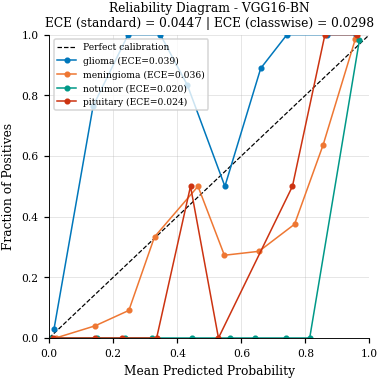

Clean single-pass on VAL   (VGG16-BN)...


clean pass:   0%|          | 0/14 [00:00<?, ?it/s]

Clean single-pass on TEST  (VGG16-BN)...


clean pass:   0%|          | 0/25 [00:00<?, ?it/s]

  params 138,597,700 | 30.94 GFLOPs | 10.45 ms/img | 338.7 img/s

Artifacts saved -> /kaggle/working/models/vgg16_best.pth (+ metrics/preds/probs/ci/calibration)


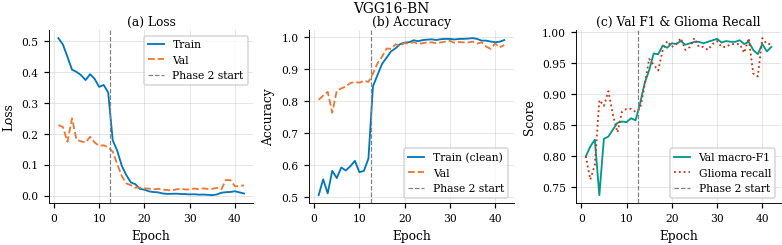


Releasing VGG16-BN from VRAM...
  GPU 0: allocated 0.03 GB | reserved 0.46 GB
  GPU 1: allocated 0.02 GB | reserved 0.23 GB

######################################################################
#  DenseNet121  (densenet121, SWA=False)
######################################################################


model.safetensors:   0%|          | 0.00/32.3M [00:00<?, ?B/s]

DenseNet121 built | params = 8,136,836 | in_features = 1024
Phase 1 trainable params: 1,182,980
PHASE 1 - DenseNet121 HEAD-ONLY TRAINING

[DenseNet121-P1] Epoch 1/12
-------------------------------------------------------


train:   0%|          | 0/74 [00:00<?, ?it/s]

val:   0%|          | 0/14 [00:00<?, ?it/s]

Train Loss: 0.6035 | Acc(clean): 0.4576
Val   Loss: 0.2922 | Acc: 0.7405
Val   F1  : 0.7218 | P: 0.7532 | R: 0.7405
LR: 4.00e-04
Per-class recall: glioma: 0.848  meningioma: 0.371  notumor: 0.986  pituitary: 0.757
  glioma checkpoint saved | GliomaR=0.8476
  best saved [F1] | F1=0.7218

[DenseNet121-P1] Epoch 2/12
-------------------------------------------------------


... (113 outputs left out)

TTA 3/5:   0%|          | 0/25 [00:00<?, ?it/s]

TTA 4/5:   0%|          | 0/25 [00:00<?, ?it/s]

TTA 5/5:   0%|          | 0/25 [00:00<?, ?it/s]

              precision    recall  f1-score   support

      glioma     0.9914    0.8625    0.9225       400
  meningioma     0.9144    0.9875    0.9495       400
     notumor     0.9547    1.0000    0.9768       400
   pituitary     0.9900    0.9925    0.9913       400

    accuracy                         0.9606      1600
   macro avg     0.9626    0.9606    0.9600      1600
weighted avg     0.9626    0.9606    0.9600      1600


Metrics - DenseNet121 (TTA x5, held-out test)
  accuracy      : 0.9606
  f1            : 0.9600
  precision     : 0.9626
  recall        : 0.9606
  kappa         : 0.9475
  mcc           : 0.9485
  mean_auc      : 0.9933
  glioma_recall : 0.8625

  Per-class:
    glioma       | Sens=0.8625 | Spec=0.9975 | AUC=0.9771
    meningioma   | Sens=0.9875 | Spec=0.9692 | AUC=0.9968
    notumor      | Sens=1.0000 | Spec=0.9842 | AUC=0.9995
    pituitary    | Sens=0.9925 | Spec=0.9967 | AUC=0.9999

Bootstrap 95% CI (1000 resamples)
-------------------------------------

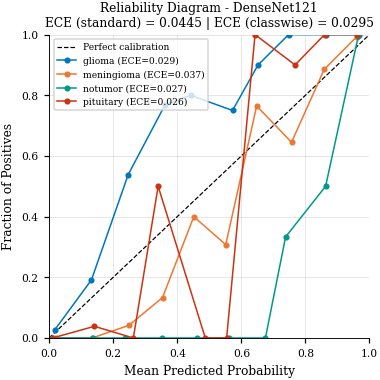

Clean single-pass on VAL   (DenseNet121)...


clean pass:   0%|          | 0/14 [00:00<?, ?it/s]

Clean single-pass on TEST  (DenseNet121)...


clean pass:   0%|          | 0/25 [00:00<?, ?it/s]

  params 8,136,836 | 5.67 GFLOPs | 19.26 ms/img | 698.0 img/s

Artifacts saved -> /kaggle/working/models/densenet121_best.pth (+ metrics/preds/probs/ci/calibration)


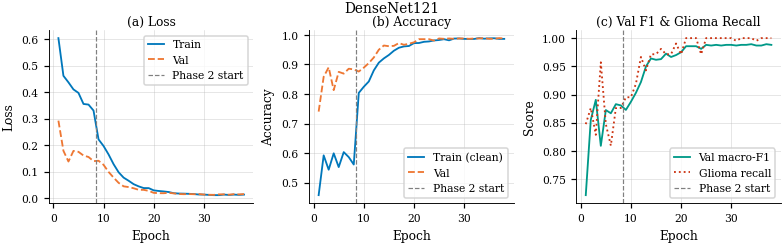


Releasing DenseNet121 from VRAM...
  GPU 0: allocated 0.03 GB | reserved 0.46 GB
  GPU 1: allocated 0.02 GB | reserved 0.23 GB

######################################################################
#  ResNet50  (resnet50, SWA=False)
######################################################################


model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

ResNet50 built | params = 25,739,588 | in_features = 2048
Phase 1 trainable params: 2,231,556
PHASE 1 - ResNet50 HEAD-ONLY TRAINING

[ResNet50-P1] Epoch 1/12
-------------------------------------------------------


train:   0%|          | 0/74 [00:00<?, ?it/s]

val:   0%|          | 0/14 [00:00<?, ?it/s]

Train Loss: 0.6362 | Acc(clean): 0.3708
Val   Loss: 0.3324 | Acc: 0.7262
Val   F1  : 0.7156 | P: 0.7488 | R: 0.7262
LR: 4.00e-04
Per-class recall: glioma: 0.738  meningioma: 0.448  notumor: 0.976  pituitary: 0.743
  glioma checkpoint saved | GliomaR=0.7381
  best saved [F1] | F1=0.7156

[ResNet50-P1] Epoch 2/12
-------------------------------------------------------


... (119 outputs left out)

TTA 3/5:   0%|          | 0/25 [00:00<?, ?it/s]

TTA 4/5:   0%|          | 0/25 [00:00<?, ?it/s]

TTA 5/5:   0%|          | 0/25 [00:00<?, ?it/s]

              precision    recall  f1-score   support

      glioma     0.9431    0.7875    0.8583       400
  meningioma     0.8480    0.8925    0.8697       400
     notumor     0.9066    0.9950    0.9487       400
   pituitary     0.9532    0.9675    0.9603       400

    accuracy                         0.9106      1600
   macro avg     0.9127    0.9106    0.9093      1600
weighted avg     0.9127    0.9106    0.9093      1600


Metrics - ResNet50 (TTA x5, held-out test)
  accuracy      : 0.9106
  f1            : 0.9093
  precision     : 0.9127
  recall        : 0.9106
  kappa         : 0.8808
  mcc           : 0.8823
  mean_auc      : 0.9835
  glioma_recall : 0.7875

  Per-class:
    glioma       | Sens=0.7875 | Spec=0.9842 | AUC=0.9592
    meningioma   | Sens=0.8925 | Spec=0.9467 | AUC=0.9786
    notumor      | Sens=0.9950 | Spec=0.9658 | AUC=0.9988
    pituitary    | Sens=0.9675 | Spec=0.9842 | AUC=0.9976

Bootstrap 95% CI (1000 resamples)
----------------------------------------

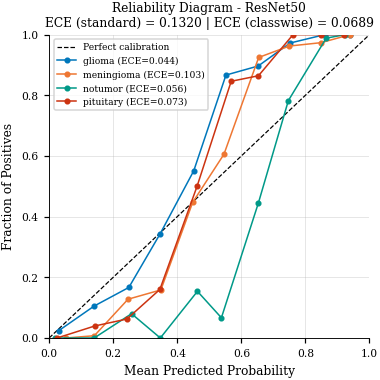

Clean single-pass on VAL   (ResNet50)...


clean pass:   0%|          | 0/14 [00:01<?, ?it/s]

Clean single-pass on TEST  (ResNet50)...


clean pass:   0%|          | 0/25 [00:01<?, ?it/s]

  params 25,739,588 | 8.18 GFLOPs | 9.38 ms/img | 768.4 img/s

Artifacts saved -> /kaggle/working/models/resnet50_best.pth (+ metrics/preds/probs/ci/calibration)


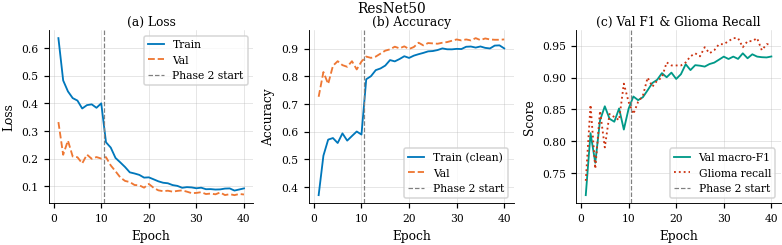


Releasing ResNet50 from VRAM...
  GPU 0: allocated 0.03 GB | reserved 0.46 GB
  GPU 1: allocated 0.02 GB | reserved 0.23 GB

######################################################################
#  Trained: ['VGG16-BN', 'DenseNet121', 'ResNet50']
######################################################################


In [22]:
all_results = {}
histories   = {}
train_stats = {}          # wall-time / epoch counts, for the complexity table (T4)

for spec in MODELS:
    key = spec["key"]
    if key not in RUN_MODELS:
        print(f"\n[skip] {spec['display']} - not in RUN_MODELS")
        continue

    print("\n" + "#" * 70)
    print(f"#  {spec['display']}  ({spec['backbone']}, SWA={spec['use_swa']})")
    print("#" * 70)

    _t0 = time.perf_counter()
    model, hist, in_features, p1_epochs = train_full_pipeline(spec)
    _train_min = (time.perf_counter() - _t0) / 60.0

    train_stats[key] = {
        "train_minutes": float(_train_min),
        "total_epochs":  int(len(hist["epoch"])),
        "p1_epochs":     int(p1_epochs),
        "p2_epochs":     int(len(hist["epoch"]) - p1_epochs),
    }
    print(f"\nTraining wall-time: {_train_min:.1f} min "
          f"({train_stats[key]['total_epochs']} epochs total)")

    all_results[spec["display"]] = evaluate_model(model, spec, in_features)
    histories[key] = {"hist": hist, "p1_epochs": p1_epochs}
    plot_history(hist, spec, p1_epochs)

    print(f"\nReleasing {spec['display']} from VRAM...")
    free_gpu("model")
    del hist, in_features, p1_epochs

print("\n" + "#" * 70)
print(f"#  Trained: {list(all_results)}")
print("#" * 70)

## §8b Rehydrate any model not trained in this session  `[Q5]`

If `RUN_MODELS` was a subset, the remaining models are loaded from their saved artifacts (this
session's `OUTPUT_DIR` first, then any attached Kaggle input). If you ran all three, this is a no-op.

In [23]:
for spec in MODELS:
    if spec["display"] in all_results:
        continue
    print(f"Loading {spec['display']} artifacts from disk...")
    all_results[spec["display"]] = load_result_from_disk(spec["key"])

# Keep the registry order regardless of how the models were obtained.
all_results = {m["display"]: all_results[m["display"]] for m in MODELS
               if m["display"] in all_results}

# Every model must have been evaluated on the same held-out test set.
_ref = all_results[next(iter(all_results))]["true"]
for name, r in all_results.items():
    assert np.array_equal(np.asarray(r["true"]), np.asarray(_ref)), \
        f"{name}: test labels differ - models were not evaluated on the same set"
print(f"Test labels identical across all {len(all_results)} models ({len(_ref)} samples).")

# [Q4] Deterministic reference model - no more 4th-decimal F1 tiebreaks.
if BEST_MODEL_OVERRIDE is not None:
    REFERENCE = SPEC_BY_KEY[BEST_MODEL_OVERRIDE]["display"]
    print(f"Reference model (pinned): {REFERENCE}")
else:
    REFERENCE = max(all_results, key=lambda k: all_results[k]["metrics"]["f1"])
    print(f"Reference model (auto, macro-F1): {REFERENCE}")

Test labels identical across all 3 models (1600 samples).
Reference model (pinned): VGG16-BN


## §9.1 Combined ROC curves

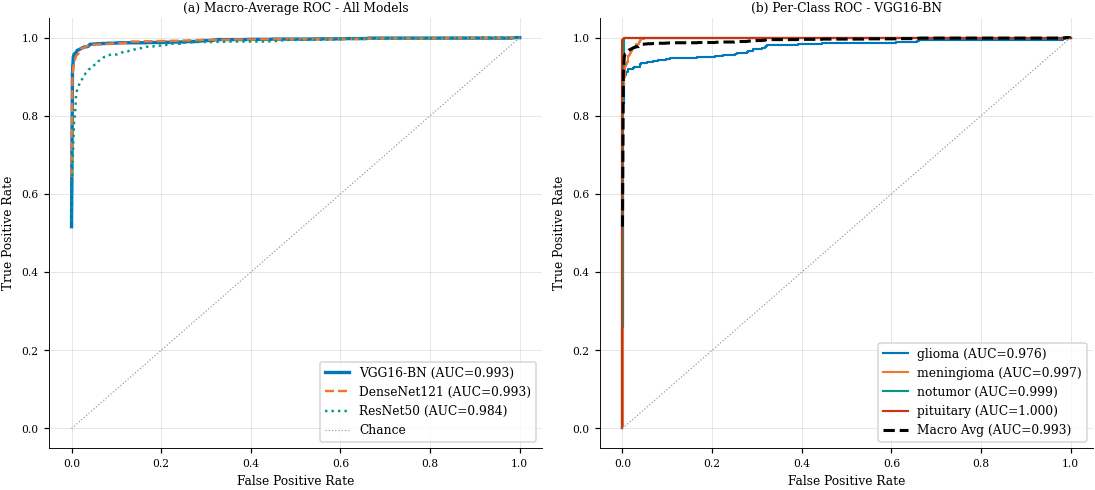

ROC curves saved.


In [24]:
def plot_roc_all(all_results, reference):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    grid = np.linspace(0, 1, 500)

    ax = axes[0]
    for name, r in all_results.items():
        yb = label_binarize(r["true"], classes=list(range(NUM_CLASSES)))
        mean_tpr = np.zeros_like(grid)
        for i in range(NUM_CLASSES):
            fpr, tpr, _ = roc_curve(yb[:, i], r["probs"][:, i])
            mean_tpr += np.interp(grid, fpr, tpr)
        mean_tpr /= NUM_CLASSES
        st = PALETTE_MODELS.get(name, {"color": "grey", "ls": "-", "lw": 1.4})
        ax.plot(grid, mean_tpr, color=st["color"], ls=st["ls"], lw=st["lw"],
                label=f"{name} (AUC={auc(grid, mean_tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="0.6", ls=":", lw=0.8, label="Chance")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.set_title("(a) Macro-Average ROC - All Models", pad=4)
    ax.legend(loc="lower right", fontsize=8); _despine(ax)

    ax = axes[1]
    r  = all_results[reference]
    yb = label_binarize(r["true"], classes=list(range(NUM_CLASSES)))
    mean_tpr = np.zeros_like(grid)
    for i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(yb[:, i], r["probs"][:, i])
        mean_tpr += np.interp(grid, fpr, tpr)
        ax.plot(fpr, tpr, color=CLASS_PALETTE[i], lw=1.4,
                label=f"{class_names[i]} (AUC={auc(fpr, tpr):.3f})")
    mean_tpr /= NUM_CLASSES
    ax.plot(grid, mean_tpr, color="black", lw=2.0, ls="--",
            label=f"Macro Avg (AUC={auc(grid, mean_tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="0.6", ls=":", lw=0.8)
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.set_title(f"(b) Per-Class ROC - {reference}", pad=4)
    ax.legend(loc="lower right", fontsize=8); _despine(ax)

    return save_fig(fig, "roc_curves")


plot_roc_all(all_results, REFERENCE)
print("ROC curves saved.")

## §9.2 Precision-Recall curves + mAP

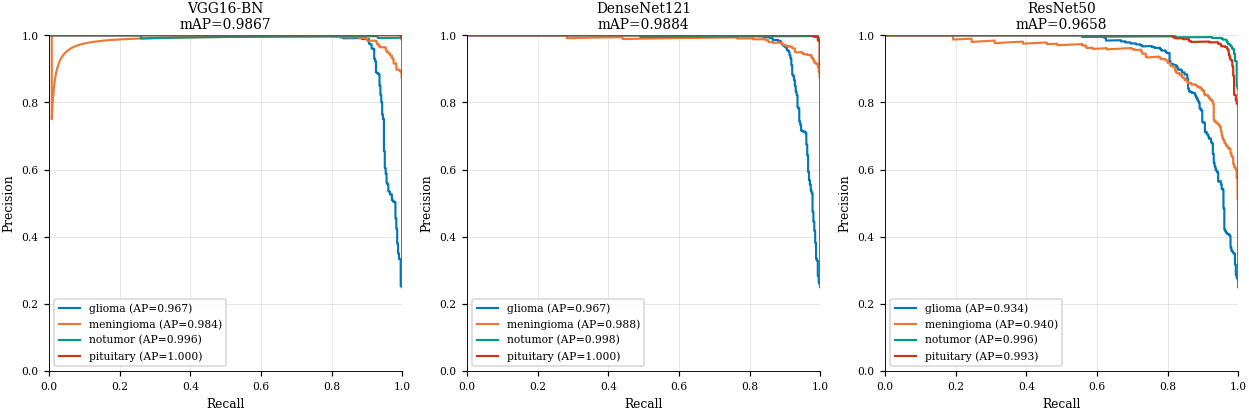


mAP per model:
  VGG16-BN      : 0.9867
  DenseNet121   : 0.9884
  ResNet50      : 0.9658


In [25]:
def plot_pr_curves(all_results):
    n = len(all_results)
    fig, axes = plt.subplots(1, n, figsize=(3.8 * n, 3.8), constrained_layout=True,
                             squeeze=False)
    for ax, (name, r) in zip(axes[0], all_results.items()):
        yb = label_binarize(r["true"], classes=list(range(NUM_CLASSES)))
        aps = []
        for i in range(NUM_CLASSES):
            prec, rec, _ = precision_recall_curve(yb[:, i], r["probs"][:, i])
            ap = average_precision_score(yb[:, i], r["probs"][:, i])
            aps.append(ap)
            ax.plot(rec, prec, color=CLASS_PALETTE[i], lw=1.4,
                    label=f"{class_names[i]} (AP={ap:.3f})")
        r["map"] = float(np.mean(aps))
        ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
        ax.set_title(f"{name}\nmAP={r['map']:.4f}", pad=4, fontsize=9)
        ax.legend(loc="lower left", fontsize=7)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); _despine(ax)
    return save_fig(fig, "pr_curves")


plot_pr_curves(all_results)
print("\nmAP per model:")
for name, r in all_results.items():
    print(f"  {name:<14}: {r['map']:.4f}")

## §9.3 Calibration comparison

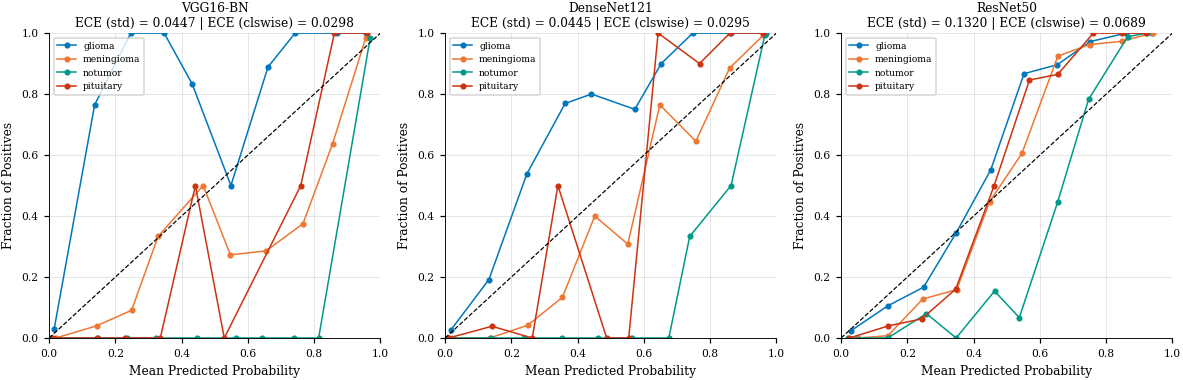

Calibration comparison saved.


In [26]:
def plot_calibration_comparison(all_results):
    n = len(all_results)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 3.5), constrained_layout=True,
                             squeeze=False)
    for ax, (name, r) in zip(axes[0], all_results.items()):
        yb = label_binarize(r["true"], classes=list(range(NUM_CLASSES)))
        for c, cname in enumerate(class_names):
            frac, mean_p = calibration_curve(yb[:, c], r["probs"][:, c],
                                             n_bins=10, strategy="uniform")
            ax.plot(mean_p, frac, marker="o", markersize=3, lw=1.0,
                    color=CLASS_PALETTE[c], label=cname)
        ax.plot([0, 1], [0, 1], "k--", lw=0.8)
        ax.set_title(f"{name}\nECE (std) = {r['ece']:.4f} | "
                     f"ECE (clswise) = {r['ece_classwise']:.4f}", pad=4, fontsize=8)
        ax.set_xlabel("Mean Predicted Probability"); ax.set_ylabel("Fraction of Positives")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.legend(fontsize=6, loc="upper left"); _despine(ax)
    return save_fig(fig, "calibration_comparison")


plot_calibration_comparison(all_results)
print("Calibration comparison saved.")

## §9.4 Confusion matrices

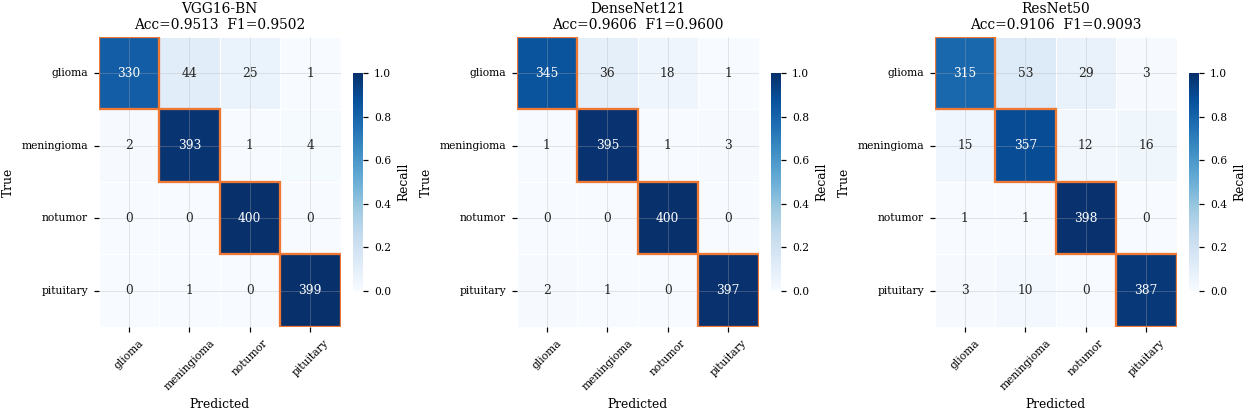

Confusion matrices saved.


In [27]:
def plot_confusion_matrices(all_results):
    n = len(all_results)
    fig, axes = plt.subplots(1, n, figsize=(3.8 * n, 3.8), constrained_layout=True,
                             squeeze=False)
    for ax, (name, r) in zip(axes[0], all_results.items()):
        cm   = confusion_matrix(r["true"], r["preds"], labels=list(range(NUM_CLASSES)))
        cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        sns.heatmap(cm_n, annot=cm, fmt="d", cmap="Blues", vmin=0.0, vmax=1.0,
                    linewidths=0.4, linecolor="white",
                    xticklabels=class_names, yticklabels=class_names,
                    annot_kws={"size": 8}, cbar_kws={"shrink": 0.75, "label": "Recall"},
                    ax=ax)
        for i in range(NUM_CLASSES):
            ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False,
                                       edgecolor="#EE7733", lw=1.5, zorder=4))
        m = r["metrics"]
        ax.set_title(f"{name}\nAcc={m['accuracy']:.4f}  F1={m['f1']:.4f}",
                     pad=5, fontsize=9)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        ax.tick_params(axis="x", rotation=45, labelsize=7)
        ax.tick_params(axis="y", rotation=0,  labelsize=7)
    return save_fig(fig, "confusion_matrices")


plot_confusion_matrices(all_results)
print("Confusion matrices saved.")

## §9.5 Per-class metric heatmap

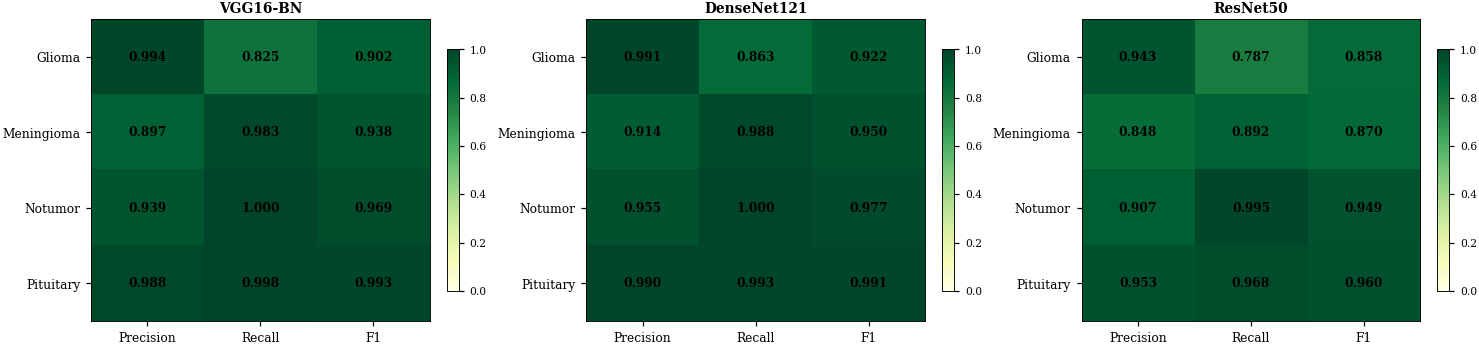

Per-class heatmap saved.


In [28]:
def plot_per_class_heatmap(all_results):
    n = len(all_results)
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 3.2), constrained_layout=True,
                             squeeze=False)
    cols = ["precision", "recall", "f1-score"]
    for ax, (name, r) in zip(axes[0], all_results.items()):
        rep = classification_report(r["true"], r["preds"], target_names=class_names,
                                    output_dict=True, zero_division=0,
                                    labels=list(range(NUM_CLASSES)))
        mat = np.array([[rep[c][k] for k in cols] for c in class_names])
        im = ax.imshow(mat, cmap="YlGn", vmin=0.0, vmax=1.0, aspect="auto")
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(["Precision", "Recall", "F1"],
                                                            fontsize=8)
        ax.set_yticks(range(NUM_CLASSES))
        ax.set_yticklabels([c.capitalize() for c in class_names], fontsize=8)
        ax.set_title(name, pad=4, fontsize=9, fontweight="bold")
        ax.grid(False)
        for i in range(NUM_CLASSES):
            for j in range(len(cols)):
                ax.text(j, i, f"{mat[i, j]:.3f}", ha="center", va="center",
                        fontsize=8, fontweight="bold",
                        color="white" if mat[i, j] < 0.5 else "black")
        plt.colorbar(im, ax=ax, shrink=0.8)
    return save_fig(fig, "per_class_heatmap")


plot_per_class_heatmap(all_results)
print("Per-class heatmap saved.")

## §10.1 McNemar's test — pairwise, all models

Exact binomial when `min(n01, n10) < 25`, chi-square otherwise. This is the correct test for
*classification-accuracy* differences on the same test set.

In [29]:
def run_mcnemar(pred_a, pred_b, y_true, name_a, name_b, verbose=True):
    ca, cb = (pred_a == y_true), (pred_b == y_true)
    n11 = int((ca & cb).sum());  n10 = int((ca & ~cb).sum())
    n01 = int((~ca & cb).sum()); n00 = int((~ca & ~cb).sum())
    exact = min(n01, n10) < 25
    res   = mcnemar_test_fn([[n11, n10], [n01, n00]], exact=exact)
    p     = float(res.pvalue)
    if verbose:
        sig = "SIGNIFICANT (p<0.05)" if p < 0.05 else "not significant"
        print(f"\nMcNemar: {name_a} vs {name_b}")
        print(f"  n11={n11}  n10={n10}  n01={n01}  n00={n00}")
        print(f"  p = {p:.4g}  [{sig}]  ({'exact' if exact else 'chi-square'})")
    return {"a": name_a, "b": name_b, "n11": n11, "n10": n10, "n01": n01, "n00": n00,
            "test": "exact" if exact else "chi-square", "p": p, "significant": p < 0.05}


print("=" * 60)
print("SIGNIFICANCE TESTING - McNemar's Test (all pairs)")
print("=" * 60)

names = list(all_results)
y_ref = np.asarray(all_results[names[0]]["true"])
mcnemar_rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        mcnemar_rows.append(run_mcnemar(
            np.asarray(all_results[names[i]]["preds"]),
            np.asarray(all_results[names[j]]["preds"]),
            y_ref, names[i], names[j]))

mcnemar_df = pd.DataFrame(mcnemar_rows)

SIGNIFICANCE TESTING - McNemar's Test (all pairs)

McNemar: VGG16-BN vs DenseNet121
  n11=1514  n10=8  n01=23  n00=55
  p = 0.01067  [SIGNIFICANT (p<0.05)]  (exact)

McNemar: VGG16-BN vs ResNet50
  n11=1439  n10=83  n01=18  n00=60
  p = 3.729e-11  [SIGNIFICANT (p<0.05)]  (exact)

McNemar: DenseNet121 vs ResNet50
  n11=1441  n10=96  n01=16  n00=47
  p = 4.378e-15  [SIGNIFICANT (p<0.05)]  (exact)


## §10.2 Wilcoxon signed-rank on confidence distributions

**This tests confidence-score distributions, not classification accuracy.** For accuracy
significance, read the McNemar results above.

In [30]:
print("=" * 60)
print("WILCOXON SIGNED-RANK - confidence distributions")
print(f"NOTE: this compares CONFIDENCE, not accuracy. Reference = {REFERENCE}")
print("=" * 60)

ref_conf  = all_results[REFERENCE]["probs"].max(axis=1)
wilc_rows = []
for name, r in all_results.items():
    if name == REFERENCE:
        continue
    other = r["probs"].max(axis=1)
    if np.all(ref_conf - other == 0):
        print(f"\n{REFERENCE} vs {name}: all differences zero - skipped")
        continue
    stat, p = wilcoxon(ref_conf, other, alternative="two-sided")
    sig = "SIGNIFICANT (p<0.05)" if p < 0.05 else "not significant"
    print(f"\n{REFERENCE} vs {name}")
    print(f"  {REFERENCE:<14} mean conf: {ref_conf.mean():.4f} +/- {ref_conf.std():.4f}")
    print(f"  {name:<14} mean conf: {other.mean():.4f} +/- {other.std():.4f}")
    print(f"  W = {stat:.2f} | p = {p:.4g}  [{sig}]")
    wilc_rows.append({"reference": REFERENCE, "other": name,
                      "ref_mean_conf": float(ref_conf.mean()),
                      "other_mean_conf": float(other.mean()),
                      "W": float(stat), "p": float(p), "significant": bool(p < 0.05)})

wilcoxon_df = pd.DataFrame(wilc_rows)

WILCOXON SIGNED-RANK - confidence distributions
NOTE: this compares CONFIDENCE, not accuracy. Reference = VGG16-BN

VGG16-BN vs DenseNet121
  VGG16-BN       mean conf: 0.9414 +/- 0.0735
  DenseNet121    mean conf: 0.9274 +/- 0.0969
  W = 581267.50 | p = 0.001378  [SIGNIFICANT (p<0.05)]

VGG16-BN vs ResNet50
  VGG16-BN       mean conf: 0.9414 +/- 0.0735
  ResNet50       mean conf: 0.7795 +/- 0.1493
  W = 9860.00 | p = 4.735e-255  [SIGNIFICANT (p<0.05)]


## §11.1 Benchmark tables → console, CSV, Markdown, LaTeX

In [31]:
_ROWS = [("Accuracy", "accuracy", "acc"), ("Macro F1", "f1", "f1"),
         ("Precision", "precision", "prec"), ("Recall", "recall", "rec"),
         ("Kappa", "kappa", "kappa"), ("MCC", "mcc", "mcc"),
         ("Mean AUC", "mean_auc", "auc"),
         ("Glioma Recall", "glioma_recall", "glioma_recall"),
         ("ECE (standard)", None, "ece_std"), ("ECE (classwise)", None, "ece_cls")]


def build_comparison_table(all_results):
    rows = []
    for name, r in all_results.items():
        m = r["metrics"]
        rows.append({
            "Model": name, "Backbone": r["backbone"],
            "Accuracy": m["accuracy"], "Macro F1": m["f1"], "MCC": m["mcc"],
            "Kappa": m["kappa"], "Mean AUC": m["mean_auc"],
            "mAP": r.get("map", float("nan")),
            "Glioma Recall": m["glioma_recall"],
            "ECE": r["ece"],
            "F1 95% CI": f"[{r['ci']['f1'][0]:.4f}, {r['ci']['f1'][1]:.4f}]",
            "AUC 95% CI": f"[{r['ci']['auc'][0]:.4f}, {r['ci']['auc'][1]:.4f}]",
            "Reference": name == REFERENCE,
        })
    return pd.DataFrame(rows)


def build_ci_table(all_results):
    rows = []
    for name, r in all_results.items():
        m, ci = r["metrics"], r["ci"]
        for disp, mkey, cikey in _ROWS:
            if mkey is not None:
                point = m[mkey]
            elif cikey == "ece_std":
                point = r["ece"]
            else:
                point = r["ece_classwise"]
            lo, hi = ci.get(cikey, (float("nan"), float("nan")))
            rows.append({"Model": name, "Metric": disp, "Point": point,
                         "CI lower": lo, "CI upper": hi})
    return pd.DataFrame(rows)


def export_tables(tables):
    """Write every table as .csv, .md and .tex."""
    written = []
    for name, df in tables.items():
        csv = os.path.join(TAB_DIR, f"{name}.csv")
        md  = os.path.join(TAB_DIR, f"{name}.md")
        tex = os.path.join(TAB_DIR, f"{name}.tex")
        df.to_csv(csv, index=False)
        with open(md, "w") as f:
            f.write(df.to_markdown(index=False, floatfmt=".4f"))
        with open(tex, "w") as f:
            f.write(df.to_latex(index=False, float_format="%.4f", escape=True))
        written += [csv, md, tex]
        print(f"  {name}: csv + md + tex")
    return written


benchmark_df = build_comparison_table(all_results)
ci_df        = build_ci_table(all_results)

print("=" * 100)
print("FINAL BENCHMARK TABLE")
print("=" * 100)
print(benchmark_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nLegend: mAP = mean Average Precision | ECE = Expected Calibration Error "
      "(standard, Guo et al. 2017)")
print("CI = 95% bootstrap confidence interval (1000 resamples)")

print("\n" + "=" * 70)
print("95% BOOTSTRAP CI - point estimate [lower, upper]")
print("=" * 70)
for name in all_results:
    print(f"\n  {name}")
    sub = ci_df[ci_df["Model"] == name]
    for _, row in sub.iterrows():
        print(f"    {row['Metric']:<16}: {row['Point']:.4f} "
              f"[{row['CI lower']:.4f}, {row['CI upper']:.4f}]")

print("\nExporting tables...")
table_files = export_tables({
    "benchmark_table": benchmark_df,
    "ci_table":        ci_df,
    "mcnemar":         mcnemar_df,
    "wilcoxon":        wilcoxon_df,
})

FINAL BENCHMARK TABLE
      Model    Backbone  Accuracy  Macro F1    MCC  Kappa  Mean AUC    mAP  Glioma Recall    ECE        F1 95% CI       AUC 95% CI  Reference
   VGG16-BN    vgg16_bn    0.9513    0.9502 0.9367 0.9350    0.9932 0.9867         0.8250 0.0447 [0.9389, 0.9600] [0.9900, 0.9958]       True
DenseNet121 densenet121    0.9606    0.9600 0.9485 0.9475    0.9933 0.9884         0.8625 0.0445 [0.9501, 0.9691] [0.9901, 0.9961]      False
   ResNet50    resnet50    0.9106    0.9093 0.8823 0.8808    0.9835 0.9658         0.7875 0.1320 [0.8952, 0.9229] [0.9792, 0.9875]      False

Legend: mAP = mean Average Precision | ECE = Expected Calibration Error (standard, Guo et al. 2017)
CI = 95% bootstrap confidence interval (1000 resamples)

95% BOOTSTRAP CI - point estimate [lower, upper]

  VGG16-BN
    Accuracy        : 0.9513 [0.9400, 0.9606]
    Macro F1        : 0.9502 [0.9389, 0.9600]
    Precision       : 0.9545 [0.9442, 0.9633]
    Recall          : 0.9513 [0.9405, 0.9606]
    Kap

## §11.2 `best_overall_model.pth` + `benchmark_results.json` + manifest  `[Q4]`

The reference model is **pinned** in `BEST_MODEL_OVERRIDE`, so the XAI notebook gets a deterministic
input. The auto-select path is still available (set the override to `None`), but in the original run
VGG16 and DenseNet121 tied at `F1 = 0.9586` and the winner was decided by float noise — which then
silently changed which model the XAI notebook explained.

In [32]:
ranked = sorted(all_results.items(), key=lambda kv: kv[1]["metrics"]["f1"], reverse=True)

print("=" * 70)
print("RANKING BY MACRO-F1 (held-out test, TTA)")
print("=" * 70)
for i, (name, r) in enumerate(ranked, 1):
    m = r["metrics"]
    tag = "  <- REFERENCE" if name == REFERENCE else ""
    print(f"  #{i}  {name:<14} | F1={m['f1']:.4f} | Acc={m['accuracy']:.4f} | "
          f"AUC={m['mean_auc']:.4f} | MCC={m['mcc']:.4f}{tag}")

# best_overall_model.pth = a copy of the reference model's checkpoint.
ref_spec = next(m for m in MODELS if m["display"] == REFERENCE)
src_ckpt = os.path.join(MODEL_DIR, ref_spec["ckpt"])
dst_ckpt = os.path.join(MODEL_DIR, "best_overall_model.pth")
if os.path.exists(src_ckpt):
    shutil.copyfile(src_ckpt, dst_ckpt)
    print(f"\nbest_overall_model.pth <- {ref_spec['ckpt']}  ({REFERENCE})")
else:
    print(f"\n[warn] {src_ckpt} not present in this session "
          f"(model was rehydrated from artifacts); best_overall_model.pth not written.")

summary = {
    "reference_model":     REFERENCE,
    "reference_selection": "pinned" if BEST_MODEL_OVERRIDE else "auto (macro-F1)",
    "ranking":             [{"model": n, **{k: v for k, v in r["metrics"].items()
                                            if isinstance(v, float)}} for n, r in ranked],
    "models": {n: {"backbone": r["backbone"], "ckpt": SPEC_BY_KEY[r["key"]]["ckpt"],
                   "eval_choice": r["eval_choice"], "metrics": r["metrics"],
                   "ci": {k: list(v) for k, v in r["ci"].items()},
                   "ece_standard": r["ece"], "ece_classwise": r["ece_classwise"]}
               for n, r in all_results.items()},
    "config": {"img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "val_frac": VAL_FRAC,
               "seed": RANDOM_SEED, "tta_runs": TTA_RUNS,
               "bootstrap_runs": BOOTSTRAP_RUNS, "class_names": list(class_names)},
    "mcnemar":  mcnemar_rows,
    "wilcoxon": wilc_rows,
}
with open(os.path.join(MODEL_DIR, "benchmark_results.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)
print("benchmark_results.json saved.")

manifest = {"models": [], "figures": [], "tables": []}
for root, _, files in os.walk(OUTPUT_DIR):
    for fn in sorted(files):
        p   = os.path.join(root, fn)
        rel = os.path.relpath(p, OUTPUT_DIR)
        rec = {"path": rel, "mb": round(os.path.getsize(p) / 1e6, 2)}
        if rel.startswith("models"):
            manifest["models"].append(rec)
        elif rel.startswith("figures"):
            manifest["figures"].append(rec)
        elif rel.startswith("tables"):
            manifest["tables"].append(rec)
with open(os.path.join(MODEL_DIR, "manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 70)
print("OUTPUT MANIFEST")
print("=" * 70)
for group in ("models", "figures", "tables"):
    print(f"\n{group}/")
    for rec in manifest[group]:
        print(f"   {rec['path']:<48} {rec['mb']:>8.2f} MB")
print(f"\nTotal: {sum(r['mb'] for g in manifest.values() for r in g):.1f} MB")

RANKING BY MACRO-F1 (held-out test, TTA)
  #1  DenseNet121    | F1=0.9600 | Acc=0.9606 | AUC=0.9933 | MCC=0.9485
  #2  VGG16-BN       | F1=0.9502 | Acc=0.9513 | AUC=0.9932 | MCC=0.9367  <- REFERENCE
  #3  ResNet50       | F1=0.9093 | Acc=0.9106 | AUC=0.9835 | MCC=0.8823

best_overall_model.pth <- vgg16_best.pth  (VGG16-BN)
benchmark_results.json saved.

OUTPUT MANIFEST

models/
   models/benchmark_results.json                        0.01 MB
   models/best_overall_model.pth                      554.47 MB
   models/densenet121_best.pth                         33.14 MB
   models/densenet121_calibration.npz                   0.00 MB
   models/densenet121_ci.npz                            0.00 MB
   models/densenet121_ckpt_best.pth                    33.14 MB
   models/densenet121_ckpt_glioma.pth                  33.14 MB
   models/densenet121_metrics.json                      0.00 MB
   models/densenet121_preds.npz                         0.03 MB
   models/densenet121_probe.npz            

---
# §13 Thesis / Conference Pack

Everything below is **analysis of results already computed** — no retraining, no change to any
reported metric. The headline numbers in §11 remain the TTA figures exactly as before.

| # | Figure | # | Table |
|---|---|---|---|
| F1 | Class distribution (train/val/test) | T1 | Dataset composition |
| F2 | Representative samples per class | T2 | Hyperparameters (full) |
| F3 | Preprocessing pipeline | T3 | Augmentation pipeline |
| F4 | Augmentation examples | T4 | Model complexity & efficiency |
| F5 | Validation-F1 curves, all models | T5 | Per-class metrics (all models) |
| F6 | LR schedule | T6 | Val-vs-test generalisation gap |
| F7 | Confusion matrices (counts + row-normalised) | T7 | Calibration ± temperature scaling |
| F8 | Per-class F1 with bootstrap CIs | T8 | Literature comparison (scaffold) |
| F9 | Val-vs-test recall gap | | |
| F10 | Reliability before/after temperature scaling | | |
| F11 | Confidence: correct vs incorrect | | |
| F12 | Misclassified exemplars | | |
| F13 | t-SNE of penultimate embeddings | | |
| F14 | Bootstrap CI forest plot | | |
| F15 | Accuracy vs computational cost | | |


## §13.1 Dataset characterisation

In [33]:
def mcol(name, default="#555555"):
    """PALETTE_MODELS stores full line styles; this pulls just the colour."""
    return PALETTE_MODELS.get(name, {}).get("color", default)


# Bootstrap CIs are stored as {key: (lo, hi)}; map them onto the metrics dict.
CI_TO_METRIC = {"acc": "accuracy", "f1": "f1", "prec": "precision", "rec": "recall",
                "kappa": "kappa", "mcc": "mcc", "auc": "mean_auc",
                "glioma_recall": "glioma_recall"}
print("Thesis-pack helpers ready.")

Thesis-pack helpers ready.


T1 - Dataset composition
     Class  Train  Val  Test (held-out)  Total
    glioma   1190  210              400   1800
meningioma   1190  210              400   1800
   notumor   1190  210              400   1800
 pituitary   1190  210              400   1800
 **Total**   4760  840             1600   7200


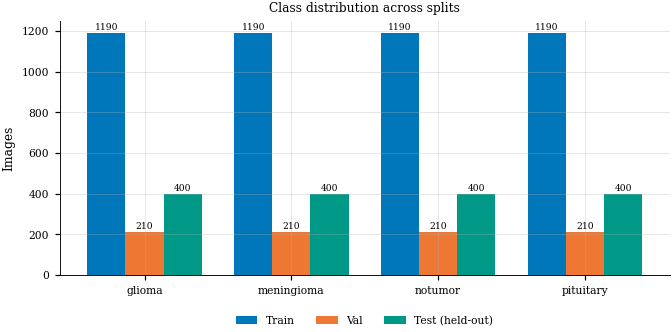

'/kaggle/working/figures/f1_class_distribution'

In [34]:
# ── T1: dataset composition ────────────────────────────────────────────────
_tr = Counter(int(l) for l in all_labels[train_idx])
_va = Counter(int(l) for l in all_labels[val_idx])
_te = Counter(int(l) for l in np.asarray(tta_dataset.targets))

dataset_rows = []
for i, c in enumerate(class_names):
    dataset_rows.append({
        "Class": c, "Train": _tr[i], "Val": _va[i], "Test (held-out)": _te[i],
        "Total": _tr[i] + _va[i] + _te[i],
    })
dataset_rows.append({
    "Class": "**Total**",
    "Train": sum(_tr.values()), "Val": sum(_va.values()),
    "Test (held-out)": sum(_te.values()),
    "Total": sum(_tr.values()) + sum(_va.values()) + sum(_te.values()),
})
dataset_df = pd.DataFrame(dataset_rows)
print("T1 - Dataset composition")
print(dataset_df.to_string(index=False))

# ── F1: class distribution ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7.16, 3.0))
x = np.arange(len(class_names))
w = 0.26
for off, (name, cnt, col) in enumerate([
        ("Train", _tr, "#0077BB"), ("Val", _va, "#EE7733"),
        ("Test (held-out)", _te, "#009988")]):
    vals = [cnt[i] for i in range(len(class_names))]
    b = ax.bar(x + (off - 1) * w, vals, w, label=name, color=col, edgecolor="none")
    ax.bar_label(b, fontsize=6, padding=1)
ax.set_xticks(x); ax.set_xticklabels(class_names)
ax.set_ylabel("Images"); ax.set_title("Class distribution across splits")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
_despine(ax)
save_fig(fig, "f1_class_distribution")

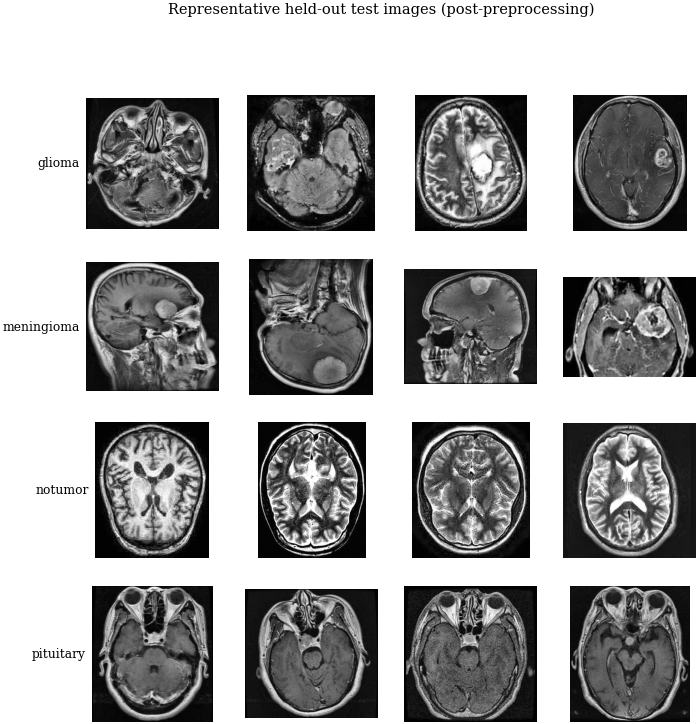

'/kaggle/working/figures/f2_class_samples'

In [35]:
# ── F2: representative samples ─────────────────────────────────────────────
rng_fig = np.random.RandomState(RANDOM_SEED)
n_show  = 4
fig, axes = plt.subplots(len(class_names), n_show,
                         figsize=(7.16, 1.85 * len(class_names)))
raw_by_cls = {c: [] for c in class_names}
for p, l in tta_dataset.samples:
    raw_by_cls[class_names[int(l)]].append(p)

for r, c in enumerate(class_names):
    picks = rng_fig.choice(raw_by_cls[c], size=min(n_show, len(raw_by_cls[c])),
                           replace=False)
    for k in range(n_show):
        ax = axes[r, k]
        ax.axis("off")
        if k < len(picks):
            ax.imshow(Image.open(picks[k]).convert("L"), cmap="gray")
        if k == 0:
            ax.set_ylabel(c, rotation=0, ha="right", va="center", fontsize=8)
            ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)
fig.suptitle("Representative held-out test images (post-preprocessing)", y=0.995)
save_fig(fig, "f2_class_samples")

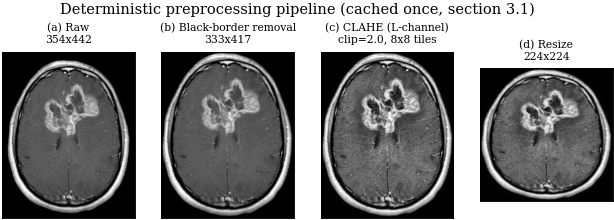

'/kaggle/working/figures/f3_preprocessing_pipeline'

In [36]:
# ── F3: preprocessing pipeline ─────────────────────────────────────────────
# Show the deterministic stages on one raw image. These are exactly the ops baked
# into the cache in section 3.1.
_raw_path = None
for cls in sorted(os.listdir(TEST_DIR)):
    d = os.path.join(TEST_DIR, cls)
    if os.path.isdir(d):
        fs = sorted(os.listdir(d))
        if fs:
            _raw_path = os.path.join(d, fs[0]); break

_raw   = Image.open(_raw_path).convert("RGB")
_crop  = RemoveBlackBorder()(_raw)
_clahe = ApplyCLAHE()(_crop)
_final = transforms.Resize((IMG_SIZE, IMG_SIZE))(_clahe)

stages = [(_raw, f"(a) Raw\n{_raw.size[0]}x{_raw.size[1]}"),
          (_crop, f"(b) Black-border removal\n{_crop.size[0]}x{_crop.size[1]}"),
          (_clahe, "(c) CLAHE (L-channel)\nclip=2.0, 8x8 tiles"),
          (_final, f"(d) Resize\n{IMG_SIZE}x{IMG_SIZE}")]

fig, axes = plt.subplots(1, 4, figsize=(7.16, 2.3))
for ax, (im, t) in zip(axes, stages):
    ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(t, fontsize=7)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Deterministic preprocessing pipeline (cached once, section 3.1)", y=1.02)
save_fig(fig, "f3_preprocessing_pipeline")

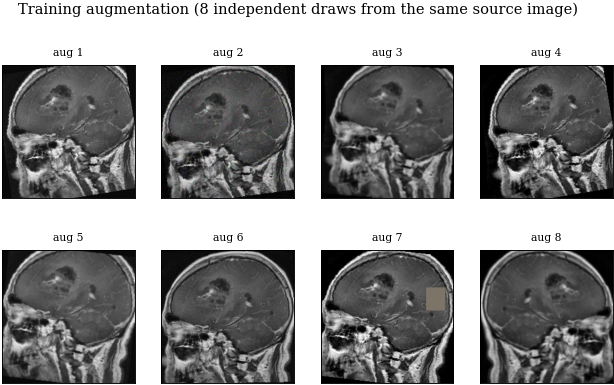

In [37]:
# ── F4: augmentation examples ──────────────────────────────────────────────
_MEAN = [0.485, 0.456, 0.406]
_STD  = [0.229, 0.224, 0.225]
_inv  = transforms.Normalize(mean=[-m / s for m, s in zip(_MEAN, _STD)],
                             std=[1.0 / s for s in _STD])

_src_path, _ = train_dataset.base.samples[train_dataset.indices[0]]
_src = train_dataset.base.loader(_src_path)

torch.manual_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)
fig, axes = plt.subplots(2, 4, figsize=(7.16, 4.0))
for i, ax in enumerate(axes.flat):
    t = train_transform(_src)
    ax.imshow(_inv(t).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"aug {i+1}", fontsize=7)
fig.suptitle("Training augmentation (8 independent draws from the same source image)",
             y=1.00)
save_fig(fig, "f4_augmentation_examples")
# restore the global RNG so nothing downstream is perturbed
torch.manual_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)

## §13.2 Reproducibility tables

`T2` is generated **from the live `CFG` globals**, so it can never drift from what was
actually run — a recurring failure mode in the old notebooks, where the methods section
described a schedule the code did not execute.

In [38]:
# ── T2: hyperparameters ────────────────────────────────────────────────────
hp_groups = [
    ("Data", [("Image size", f"{IMG_SIZE}x{IMG_SIZE}"),
              ("Batch size", BATCH_SIZE),
              ("Train/val split", f"{100*(1-VAL_FRAC):.0f}% / {100*VAL_FRAC:.0f}% (stratified)"),
              ("Test set", "Held-out `Testing/` directory (never seen in training)"),
              ("Random seed", RANDOM_SEED)]),
    ("Loss", [("Criterion", "Focal loss"),
              ("Focal gamma", FOCAL_GAMMA),
              ("Label smoothing", LABEL_SMOOTHING),
              ("Class weighting", "Inverse-frequency, normalised"),
              ("Glioma weight boost", f"x{GLIOMA_BOOST}")]),
    ("Phase 1 (head only)", [("Optimiser", "AdamW"),
                             ("LR", f"{LR_P1:.0e}"),
                             ("Epochs (max)", EPOCHS_P1),
                             ("Warmup epochs", WARMUP_P1),
                             ("Early-stop patience", PATIENCE_P1),
                             ("Schedule", "Linear warmup -> cosine"),
                             ("Regularisation", "MixUp + CutMix"),
                             ("Backbone", "Frozen (weights AND BatchNorm)")]),
    ("Phase 2 (fine-tune)", [("Optimiser", "AdamW"),
                             ("LR (head)", f"{LR_P2_HEAD:.0e}"),
                             ("LR (backbone)", f"{LR_P2_BACKBONE:.0e}"),
                             ("Weight decay", "1e-4"),
                             ("Epochs (max)", EPOCHS_P2),
                             ("Warmup epochs", WARMUP_P2),
                             ("Early-stop patience", PATIENCE_P2),
                             ("Schedule", "Linear warmup -> cosine"),
                             ("Gradient clipping", f"max-norm {GRAD_CLIP_NORM}"),
                             ("Mixed precision", "fp16 autocast + GradScaler")]),
    ("SWA (VGG16-BN only)", [("Start", f"{SWA_START_FRAC:.0%} of Phase 2"),
                             ("SWA LR", f"{SWA_LR:.0e}"),
                             ("BN recalibration", "Clean (non-augmented) train images"),
                             ("Early stopping", "Disabled during the SWA window")]),
    ("Evaluation", [("TTA runs", TTA_RUNS),
                    ("Bootstrap resamples", BOOTSTRAP_RUNS),
                    ("Significance tests", "McNemar (pairwise), Wilcoxon signed-rank")]),
]
hp_rows = [{"Group": g, "Hyperparameter": k, "Value": str(v)}
           for g, items in hp_groups for k, v in items]
hyperparams_df = pd.DataFrame(hp_rows)
print("T2 - Hyperparameters (generated from the live CFG)")
print(hyperparams_df.to_string(index=False))

# ── T3: augmentation ───────────────────────────────────────────────────────
aug_df = pd.DataFrame([
    {"Stage": "Preprocessing (deterministic)", "Operation": "Black-border removal",
     "Parameters": "threshold=15, pad=4", "Applied to": "Train / Val / Test"},
    {"Stage": "Preprocessing (deterministic)", "Operation": "CLAHE (L channel of LAB)",
     "Parameters": "clip=2.0, tiles=8x8", "Applied to": "Train / Val / Test"},
    {"Stage": "Geometric", "Operation": "Resize + RandomCrop",
     "Parameters": f"{IMG_SIZE+24} -> {IMG_SIZE}", "Applied to": "Train"},
    {"Stage": "Geometric", "Operation": "Random horizontal flip",
     "Parameters": "p=0.5", "Applied to": "Train"},
    {"Stage": "Geometric", "Operation": "Random rotation",
     "Parameters": "+/-10 deg", "Applied to": "Train"},
    {"Stage": "Geometric", "Operation": "Random shear",
     "Parameters": "5 deg, p=0.2", "Applied to": "Train"},
    {"Stage": "Photometric", "Operation": "Colour jitter",
     "Parameters": "brightness=0.15, contrast=0.15", "Applied to": "Train"},
    {"Stage": "Photometric", "Operation": "Gaussian blur",
     "Parameters": "k=3, sigma in [0.1, 2.0], p=0.3", "Applied to": "Train"},
    {"Stage": "Photometric", "Operation": "Gaussian noise",
     "Parameters": "sigma=0.03, p=0.3", "Applied to": "Train"},
    {"Stage": "Occlusion", "Operation": "Random erasing",
     "Parameters": "p=0.10, scale=(0.02, 0.08)", "Applied to": "Train"},
    {"Stage": "Batch-level", "Operation": "MixUp",
     "Parameters": f"alpha={MIXUP_ALPHA}", "Applied to": "Train (Phase 1)"},
    {"Stage": "Batch-level", "Operation": "CutMix",
     "Parameters": f"alpha={CUTMIX_ALPHA}", "Applied to": "Train (Phase 1)"},
    {"Stage": "Inference", "Operation": "Test-time augmentation",
     "Parameters": f"{TTA_RUNS}x (crop, +/-5 deg, 3 deg shear; NO h-flip)",
     "Applied to": "Test"},
])
print("\nT3 - Augmentation pipeline")
print(aug_df.to_string(index=False))

T2 - Hyperparameters (generated from the live CFG)
              Group      Hyperparameter                                                  Value
               Data          Image size                                                224x224
               Data          Batch size                                                     64
               Data     Train/val split                                 85% / 15% (stratified)
               Data            Test set Held-out `Testing/` directory (never seen in training)
               Data         Random seed                                                     42
               Loss           Criterion                                             Focal loss
               Loss         Focal gamma                                                    2.5
               Loss     Label smoothing                                                    0.1
               Loss     Class weighting                          Inverse-frequency, normalised

## §13.3 Complexity and efficiency

Latency is measured **batch-1 on a single GPU using the unwrapped module** — `DataParallel`'s
scatter/gather would dominate and is not what a deployment latency figure should report.
Throughput is measured at the training batch size, which is how you would actually run inference.

T4 - Model complexity and efficiency
      Model    Backbone  Params (M)  Backbone (M)  Head (M)  Feature dim  GFLOPs  Size (MB)  Latency (ms/img)  Throughput (img/s)  Train time (min)  Epochs run  Macro F1
   VGG16-BN    vgg16_bn      138.60        134.27      4.33         4096   30.94      554.4             10.45               338.7              31.6          42    0.9502
DenseNet121 densenet121        8.14          6.95      1.18         1024    5.67       32.5             19.26               698.0              33.5          38    0.9600
   ResNet50    resnet50       25.74         23.51      2.23         2048    8.18      103.0              9.38               768.4              25.0          40    0.9093


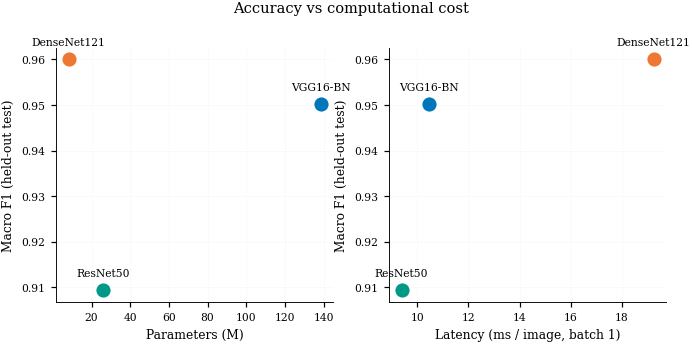

'/kaggle/working/figures/f15_accuracy_vs_cost'

In [39]:
# ── T4: complexity & efficiency ────────────────────────────────────────────
cx_rows = []
for name, r in all_results.items():
    p = r.get("profile")
    if p is None:
        continue
    tr = train_stats.get(r["key"], {})
    cx_rows.append({
        "Model": name,
        "Backbone": r["backbone"],
        "Params (M)": p["params_total"] / 1e6,
        "Backbone (M)": p["params_backbone"] / 1e6,
        "Head (M)": p["params_head"] / 1e6,
        "Feature dim": p["in_features"],
        "GFLOPs": p["gflops"],
        "Size (MB)": p["size_mb"],
        "Latency (ms/img)": p["latency_ms"],
        "Throughput (img/s)": p["throughput_ips"],
        "Train time (min)": tr.get("train_minutes", float("nan")),
        "Epochs run": tr.get("total_epochs", float("nan")),
        "Macro F1": r["metrics"]["f1"],
    })
complexity_df = pd.DataFrame(cx_rows).round(
    {"Params (M)": 2, "Backbone (M)": 2, "Head (M)": 2, "GFLOPs": 2,
     "Size (MB)": 1, "Latency (ms/img)": 2, "Throughput (img/s)": 1,
     "Train time (min)": 1, "Macro F1": 4})
print("T4 - Model complexity and efficiency")
print(complexity_df.to_string(index=False))

# ── F15: accuracy vs cost ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(7.16, 3.0))
for ax, xcol, xlab in [(axes[0], "Params (M)", "Parameters (M)"),
                       (axes[1], "Latency (ms/img)", "Latency (ms / image, batch 1)")]:
    for _, row in complexity_df.iterrows():
        ax.scatter(row[xcol], row["Macro F1"], s=110,
                   color=mcol(row["Model"]),
                   edgecolor="white", linewidth=1.2, zorder=3)
        ax.annotate(row["Model"], (row[xcol], row["Macro F1"]),
                    textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=7)
    ax.set_xlabel(xlab); ax.set_ylabel("Macro F1 (held-out test)")
    ax.grid(alpha=0.25, ls=":")
    _despine(ax)
fig.suptitle("Accuracy vs computational cost", y=1.02)
save_fig(fig, "f15_accuracy_vs_cost")

## §13.4 Training dynamics

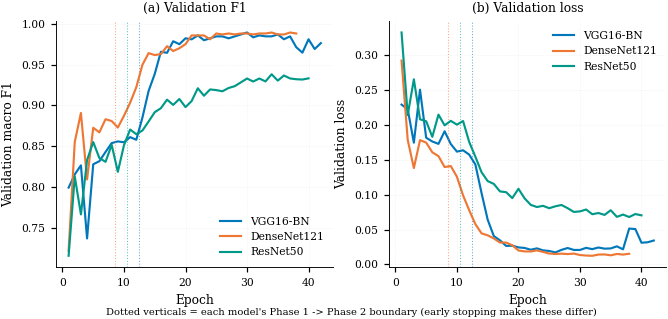

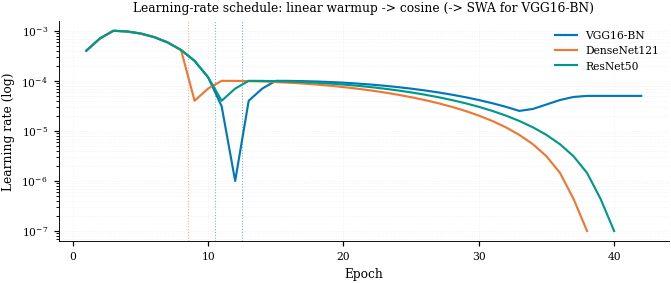

'/kaggle/working/figures/f6_lr_schedule'

In [40]:
# ── F5: validation F1, all models ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.9))
for key, h in histories.items():
    name = SPEC_BY_KEY[key]["display"]
    hist, p1 = h["hist"], h["p1_epochs"]
    col = mcol(name)
    ep = np.arange(1, len(hist["val_f1"]) + 1)
    axes[0].plot(ep, hist["val_f1"],   color=col, lw=1.4, label=name)
    axes[1].plot(ep, hist["val_loss"], color=col, lw=1.4, label=name)
    axes[0].axvline(p1 + 0.5, color=col, ls=":", lw=0.7, alpha=0.6)
    axes[1].axvline(p1 + 0.5, color=col, ls=":", lw=0.7, alpha=0.6)

axes[0].set_ylabel("Validation macro F1"); axes[0].set_title("(a) Validation F1")
axes[1].set_ylabel("Validation loss");     axes[1].set_title("(b) Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(frameon=False, fontsize=7)
    ax.grid(alpha=0.25, ls=":"); _despine(ax)
fig.text(0.5, -0.04, "Dotted verticals = each model's Phase 1 -> Phase 2 boundary "
                     "(early stopping makes these differ)", ha="center", fontsize=6.5)
save_fig(fig, "f5_val_curves_all_models")

# ── F6: LR schedule ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7.16, 2.6))
for key, h in histories.items():
    name = SPEC_BY_KEY[key]["display"]
    lrs  = h["hist"]["lr"]
    ax.plot(np.arange(1, len(lrs) + 1), lrs, lw=1.4,
            color=mcol(name), label=name)
    ax.axvline(h["p1_epochs"] + 0.5, color=mcol(name),
               ls=":", lw=0.7, alpha=0.6)
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("Learning rate (log)")
ax.set_title("Learning-rate schedule: linear warmup -> cosine (-> SWA for VGG16-BN)")
ax.legend(frameon=False, fontsize=7); ax.grid(alpha=0.25, ls=":", which="both")
_despine(ax)
save_fig(fig, "f6_lr_schedule")

## §13.5 Detailed per-class results

T5 - Per-class metrics (held-out test, TTA)
      Model      Class  Support  Precision  Recall (Sens.)  Specificity     F1    AUC
   VGG16-BN     glioma      400     0.9940          0.8250       0.9983 0.9016 0.9761
   VGG16-BN meningioma      400     0.8973          0.9825       0.9625 0.9379 0.9974
   VGG16-BN    notumor      400     0.9390          1.0000       0.9783 0.9685 0.9993
   VGG16-BN  pituitary      400     0.9876          0.9975       0.9958 0.9925 1.0000
DenseNet121     glioma      400     0.9914          0.8625       0.9975 0.9225 0.9771
DenseNet121 meningioma      400     0.9144          0.9875       0.9692 0.9495 0.9968
DenseNet121    notumor      400     0.9547          1.0000       0.9842 0.9768 0.9995
DenseNet121  pituitary      400     0.9900          0.9925       0.9967 0.9913 0.9999
   ResNet50     glioma      400     0.9431          0.7875       0.9842 0.8583 0.9592
   ResNet50 meningioma      400     0.8480          0.8925       0.9467 0.8697 0.9786
   ResNet5

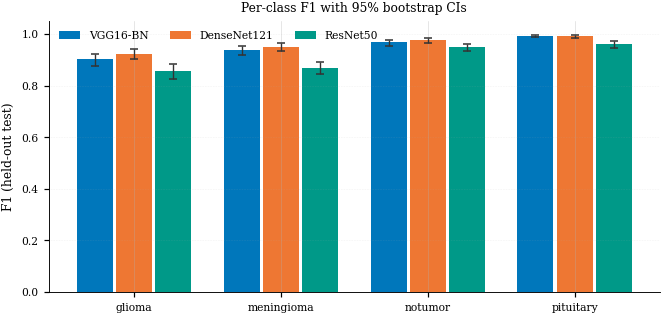

'/kaggle/working/figures/f8_per_class_f1_ci'

In [41]:
# ── T5: per-class metrics ──────────────────────────────────────────────────
pc_rows = []
for name, r in all_results.items():
    m = r["metrics"]
    cm = confusion_matrix(r["true"], r["preds"])
    prec = precision_score(r["true"], r["preds"], average=None, zero_division=0)
    f1s  = f1_score(r["true"], r["preds"], average=None, zero_division=0)
    for i, c in enumerate(class_names):
        pc_rows.append({
            "Model": name, "Class": c,
            "Support": int(cm[i].sum()),
            "Precision": prec[i],
            "Recall (Sens.)": m["sensitivity"][i],
            "Specificity": m["specificity"][i],
            "F1": f1s[i],
            "AUC": m["per_class_auc"][i],
        })
per_class_df = pd.DataFrame(pc_rows).round(4)
print("T5 - Per-class metrics (held-out test, TTA)")
print(per_class_df.to_string(index=False))

# ── F8: per-class F1 with bootstrap CIs ────────────────────────────────────
def _bootstrap_per_class_f1(y_true, y_pred, n=400, seed=RANDOM_SEED):
    rng = np.random.RandomState(seed)
    N   = len(y_true)
    out = np.zeros((n, len(class_names)))
    for b in range(n):
        idx = rng.randint(0, N, N)
        out[b] = f1_score(y_true[idx], y_pred[idx], average=None,
                          labels=list(range(len(class_names))), zero_division=0)
    return np.percentile(out, 2.5, axis=0), np.percentile(out, 97.5, axis=0)

fig, ax = plt.subplots(figsize=(7.16, 3.2))
names = list(all_results.keys())
w = 0.8 / len(names)
x = np.arange(len(class_names))
for j, name in enumerate(names):
    r  = all_results[name]
    f1s = f1_score(r["true"], r["preds"], average=None,
                   labels=list(range(len(class_names))), zero_division=0)
    lo, hi = _bootstrap_per_class_f1(r["true"], r["preds"])
    pos = x + (j - (len(names) - 1) / 2) * w
    ax.bar(pos, f1s, w * 0.92, label=name,
           color=mcol(name), edgecolor="none")
    ax.errorbar(pos, f1s, yerr=[f1s - lo, hi - f1s], fmt="none",
                ecolor="#333", elinewidth=0.9, capsize=2.5)
ax.set_xticks(x); ax.set_xticklabels(class_names)
ax.set_ylabel("F1 (held-out test)"); ax.set_ylim(0, 1.05)
ax.set_title("Per-class F1 with 95% bootstrap CIs")
ax.legend(frameon=False, ncol=3, fontsize=7)
ax.grid(axis="y", alpha=0.25, ls=":"); _despine(ax)
save_fig(fig, "f8_per_class_f1_ci")

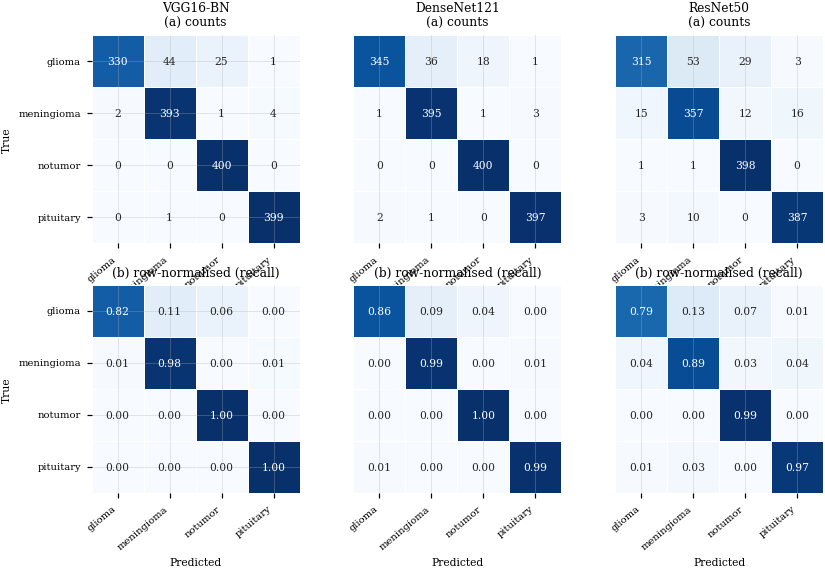

'/kaggle/working/figures/f7_confusion_matrices_full'

In [42]:
# ── F7: confusion matrices, counts + row-normalised ────────────────────────
n = len(all_results)
fig, axes = plt.subplots(2, n, figsize=(2.5 * n + 1.2, 5.4))
axes = np.atleast_2d(axes)
for j, (name, r) in enumerate(all_results.items()):
    cm   = confusion_matrix(r["true"], r["preds"])
    cmn  = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names if j == 0 else False,
                ax=axes[0, j], annot_kws={"size": 7}, square=True, linewidths=0.4)
    axes[0, j].set_title(f"{name}\n(a) counts", fontsize=8)

    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=class_names, yticklabels=class_names if j == 0 else False,
                ax=axes[1, j], annot_kws={"size": 7}, square=True, linewidths=0.4)
    axes[1, j].set_title("(b) row-normalised (recall)", fontsize=8)

    for ax in (axes[0, j], axes[1, j]):
        ax.set_xlabel("Predicted", fontsize=7)
        if j == 0:
            ax.set_ylabel("True", fontsize=7)
        ax.tick_params(labelsize=6.5)
        plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save_fig(fig, "f7_confusion_matrices_full")

## §13.6 Generalisation gap — validation vs held-out test

This is the most substantive empirical finding in the benchmark, and nothing in the original
notebooks plotted it.

Validation is a stratified 15 % slice of `Training/`. Test is the dataset's separate `Testing/`
directory. If they were drawn from the same distribution, per-class recall should agree within
sampling noise. Watch what glioma does — **across all three architectures**, which is what rules
out a modelling artefact and points to a genuine covariate shift between the two directories.

T6 - Validation vs held-out-test per-class recall
      Model      Class  Val recall  Test recall  Gap (val - test)
   VGG16-BN     glioma      0.9810       0.8250            0.1560
   VGG16-BN meningioma      0.9857       0.9825            0.0032
   VGG16-BN    notumor      0.9952       1.0000           -0.0048
   VGG16-BN  pituitary      0.9952       0.9975           -0.0023
DenseNet121     glioma      1.0000       0.8625            0.1375
DenseNet121 meningioma      0.9762       0.9875           -0.0113
DenseNet121    notumor      0.9952       1.0000           -0.0048
DenseNet121  pituitary      0.9857       0.9925           -0.0068
   ResNet50     glioma      0.9476       0.7875            0.1601
   ResNet50 meningioma      0.9000       0.8925            0.0075
   ResNet50    notumor      0.9810       0.9950           -0.0140
   ResNet50  pituitary      0.9238       0.9675           -0.0437

Mean gap per class (averaged over models):
Class
glioma        0.1512
meningioma   -0.0002


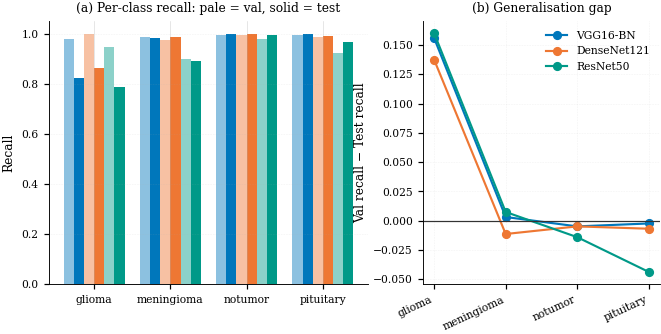

'/kaggle/working/figures/f9_val_test_generalisation_gap'

In [43]:
# ── T6 + F9: val-vs-test per-class recall ──────────────────────────────────
gap_rows = []
for name, r in all_results.items():
    if r.get("val_true") is None:
        continue
    v_rec = recall_score(r["val_true"], r["val_pred"], average=None,
                         labels=list(range(len(class_names))), zero_division=0)
    t_rec = recall_score(r["true"], r["preds"], average=None,
                         labels=list(range(len(class_names))), zero_division=0)
    for i, c in enumerate(class_names):
        gap_rows.append({"Model": name, "Class": c,
                         "Val recall": v_rec[i], "Test recall": t_rec[i],
                         "Gap (val - test)": v_rec[i] - t_rec[i]})
gap_df = pd.DataFrame(gap_rows).round(4)
print("T6 - Validation vs held-out-test per-class recall")
print(gap_df.to_string(index=False))
print("\nMean gap per class (averaged over models):")
print(gap_df.groupby("Class")["Gap (val - test)"].mean().round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(7.16, 3.1),
                         gridspec_kw={"width_ratios": [1.35, 1]})
names = list(gap_df["Model"].unique())
x = np.arange(len(class_names)); w = 0.8 / (2 * len(names))
for j, name in enumerate(names):
    sub = gap_df[gap_df["Model"] == name].set_index("Class").loc[class_names]
    base = x + (j - (len(names) - 1) / 2) * 2 * w
    col = mcol(name)
    axes[0].bar(base - w / 2, sub["Val recall"], w, color=col, alpha=0.45,
                edgecolor="none", label=f"{name} — val" if j == 0 else None)
    axes[0].bar(base + w / 2, sub["Test recall"], w, color=col,
                edgecolor="none", label=f"{name} — test" if j == 0 else None)
axes[0].set_xticks(x); axes[0].set_xticklabels(class_names)
axes[0].set_ylabel("Recall"); axes[0].set_ylim(0, 1.05)
axes[0].set_title("(a) Per-class recall: pale = val, solid = test", fontsize=8)
_despine(axes[0]); axes[0].grid(axis="y", alpha=0.25, ls=":")

for j, name in enumerate(names):
    sub = gap_df[gap_df["Model"] == name].set_index("Class").loc[class_names]
    axes[1].plot(class_names, sub["Gap (val - test)"], "o-", lw=1.4, ms=5,
                 color=mcol(name), label=name)
axes[1].axhline(0, color="#333", lw=0.8)
axes[1].set_ylabel("Val recall − Test recall")
axes[1].set_title("(b) Generalisation gap", fontsize=8)
axes[1].legend(frameon=False, fontsize=7)
axes[1].grid(alpha=0.25, ls=":"); _despine(axes[1])
plt.setp(axes[1].get_xticklabels(), rotation=25, ha="right")
save_fig(fig, "f9_val_test_generalisation_gap")

## §13.7 Calibration and temperature scaling

A single scalar temperature `T` is fitted on the **validation** logits by minimising NLL, then
applied to the **test** logits. It cannot change any prediction (softmax is monotone in the
logits, so `argmax` is invariant) — accuracy, F1, MCC and AUC are all untouched. It only
rescales confidence.

This is fitted on validation and applied to test — never fitted on test.

Note these numbers are computed on the **clean single-pass** logits, because TTA-averaged
probabilities have no logits to rescale. The headline metrics in §11 remain the TTA figures.

In [44]:
def fit_temperature(val_logits, val_labels, max_iter=200):
    """Fit a single scalar T by minimising NLL on the validation set (Guo et al., 2017)."""
    logits = torch.from_numpy(val_logits).float()
    labels = torch.from_numpy(val_labels).long()
    log_T  = torch.zeros(1, requires_grad=True)       # optimise log T -> T > 0 always
    opt    = torch.optim.LBFGS([log_T], lr=0.1, max_iter=max_iter)

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(logits / log_T.exp(), labels)
        loss.backward()
        return loss

    opt.step(closure)
    T = float(log_T.exp().item())

    # Numerical guard. The accuracy invariant (softmax is monotone -> argmax is
    # unchanged) holds mathematically for ANY T > 0, but at absurd magnitudes
    # logits/T underflows, the softmax collapses to uniform, and argmax ties break
    # arbitrarily. A fit outside this range means the LBFGS overfit a tiny validation
    # set, not that the model needs T=30000. Clamp and shout.
    if not (0.05 <= T <= 20.0):
        print(f"   [!!] Fitted T = {T:.4g} is degenerate "
              f"(val n={len(val_labels)}). Clamping to [0.05, 20]. "
              f"Treat this model's calibration numbers as unreliable.")
        T = float(np.clip(T, 0.05, 20.0))
    return T


def calibration_stats(logits, labels, T=1.0, n_bins=15):
    p = torch.softmax(torch.from_numpy(logits).float() / T, dim=1).numpy()
    conf, pred = p.max(1), p.argmax(1)
    correct = (pred == labels).astype(float)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = mce = 0.0
    for b in range(n_bins):
        m = (conf > edges[b]) & (conf <= edges[b + 1]) if b else (conf >= 0) & (conf <= edges[1])
        if m.sum() == 0:
            continue
        gap = abs(correct[m].mean() - conf[m].mean())
        ece += m.mean() * gap
        mce = max(mce, gap)

    oh    = np.eye(p.shape[1])[labels]
    brier = float(np.mean(np.sum((p - oh) ** 2, axis=1)))
    nll   = float(F.cross_entropy(torch.from_numpy(logits).float() / T,
                                  torch.from_numpy(labels).long()).item())
    return {"ECE": float(ece), "MCE": float(mce), "NLL": nll, "Brier": brier,
            "Mean conf": float(conf.mean()), "Accuracy": float(correct.mean())}


cal_rows, temps = [], {}
for name, r in all_results.items():
    if r.get("val_logit") is None:
        continue
    T = fit_temperature(r["val_logit"], r["val_true"])
    temps[name] = T
    pre  = calibration_stats(r["clean_logit"], r["clean_true"], T=1.0)
    post = calibration_stats(r["clean_logit"], r["clean_true"], T=T)
    for stage, s in (("Uncalibrated (T=1)", pre), (f"Temperature-scaled (T={T:.3f})", post)):
        cal_rows.append({"Model": name, "Stage": stage, **s})
    print(f"{name:<13} T = {T:.4f}  |  ECE {pre['ECE']:.4f} -> {post['ECE']:.4f}   "
          f"NLL {pre['NLL']:.4f} -> {post['NLL']:.4f}   "
          f"(accuracy unchanged: {pre['Accuracy']:.4f} == {post['Accuracy']:.4f})")

    # Diagnostics. T is reported exactly as fitted (that IS the method) -- these are
    # warnings, not corrections.
    if not (0.5 <= T <= 5.0):
        print(f"   [!] T={T:.3f} is extreme. With a small validation set the LBFGS fit "
              f"can overfit. Check len(val)={len(r['val_true'])}.")
    if post["ECE"] > pre["ECE"]:
        print(f"   [!] Temperature scaling did NOT improve ECE "
              f"({pre['ECE']:.4f} -> {post['ECE']:.4f}). Report this honestly; it means "
              f"a single global scalar does not fit this model's miscalibration.")
    assert abs(pre["Accuracy"] - post["Accuracy"]) < 1e-12, \
        "temperature scaling must never change a prediction"

calibration_df = pd.DataFrame(cal_rows).round(4)
print("\nT7 - Calibration, before and after temperature scaling")
print(calibration_df.to_string(index=False))

VGG16-BN      T = 0.5609  |  ECE 0.0421 -> 0.0338   NLL 0.1714 -> 0.2079   (accuracy unchanged: 0.9525 == 0.9525)
DenseNet121   T = 0.4738  |  ECE 0.0359 -> 0.0294   NLL 0.1929 -> 0.2348   (accuracy unchanged: 0.9525 == 0.9525)
   [!] T=0.474 is extreme. With a small validation set the LBFGS fit can overfit. Check len(val)=840.
ResNet50      T = 0.4437  |  ECE 0.1182 -> 0.0260   NLL 0.4009 -> 0.3775   (accuracy unchanged: 0.8931 == 0.8931)
   [!] T=0.444 is extreme. With a small validation set the LBFGS fit can overfit. Check len(val)=840.

T7 - Calibration, before and after temperature scaling
      Model                        Stage    ECE    MCE    NLL  Brier  Mean conf  Accuracy
   VGG16-BN           Uncalibrated (T=1) 0.0421 0.4158 0.1714 0.0719     0.9422    0.9525
   VGG16-BN Temperature-scaled (T=0.561) 0.0338 0.5103 0.2079 0.0789     0.9863    0.9525
DenseNet121           Uncalibrated (T=1) 0.0359 0.6689 0.1929 0.0809     0.9188    0.9525
DenseNet121 Temperature-scaled (T=0.47

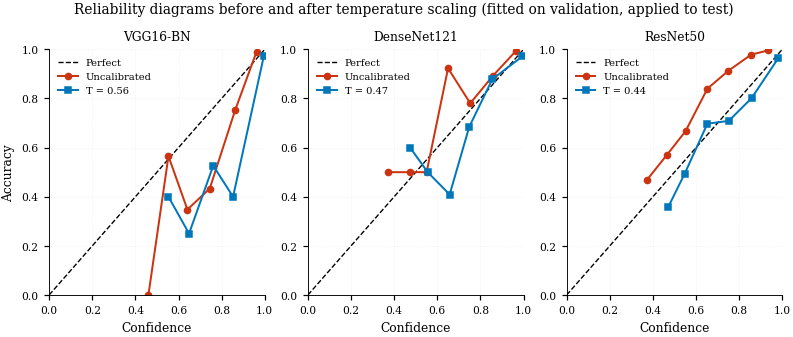

'/kaggle/working/figures/f10_temperature_scaling'

In [45]:
# ── F10: reliability before / after temperature scaling ────────────────────
n = len(temps)
fig, axes = plt.subplots(1, max(n, 1), figsize=(2.6 * max(n, 1) + 0.8, 2.9), squeeze=False)
for j, (name, T) in enumerate(temps.items()):
    ax = axes[0, j]
    r  = all_results[name]
    ax.plot([0, 1], [0, 1], "k--", lw=0.9, label="Perfect")
    for lab, tt, col, mk in [("Uncalibrated", 1.0, "#CC3311", "o"),
                             (f"T = {T:.2f}", T, "#0077BB", "s")]:
        p    = torch.softmax(torch.from_numpy(r["clean_logit"]).float() / tt, 1).numpy()
        conf = p.max(1)
        corr = (p.argmax(1) == r["clean_true"]).astype(float)
        edges = np.linspace(0, 1, 11)
        xs, ys = [], []
        for b in range(10):
            m = (conf > edges[b]) & (conf <= edges[b + 1])
            if m.sum() >= 3:
                xs.append(conf[m].mean()); ys.append(corr[m].mean())
        ax.plot(xs, ys, mk + "-", color=col, ms=4, lw=1.3, label=lab)
    ax.set_title(name, fontsize=8)
    ax.set_xlabel("Confidence")
    if j == 0:
        ax.set_ylabel("Accuracy")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=6.5, loc="upper left")
    ax.grid(alpha=0.25, ls=":"); _despine(ax)
fig.suptitle("Reliability diagrams before and after temperature scaling "
             "(fitted on validation, applied to test)", y=1.03, fontsize=9)
save_fig(fig, "f10_temperature_scaling")

## §13.8 Error analysis

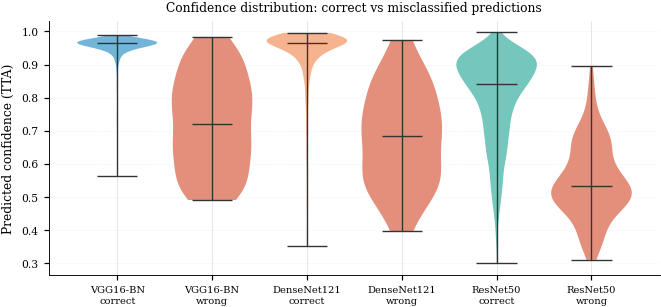

'/kaggle/working/figures/f11_confidence_correct_vs_wrong'

In [46]:
# ── F11: confidence, correct vs incorrect ──────────────────────────────────
fig, ax = plt.subplots(figsize=(7.16, 3.0))
data, labels, colors = [], [], []
for name, r in all_results.items():
    conf = r["probs"].max(1)
    ok   = r["preds"] == r["true"]
    data += [conf[ok], conf[~ok]]
    labels += [f"{name}\ncorrect", f"{name}\nwrong"]
    colors += [mcol(name), "#CC3311"]

parts = ax.violinplot(data, showmedians=True, widths=0.85)
for pc, c in zip(parts["bodies"], colors):
    pc.set_facecolor(c); pc.set_alpha(0.55); pc.set_edgecolor("none")
for k in ("cmedians", "cbars", "cmins", "cmaxes"):
    if k in parts:
        parts[k].set_color("#333"); parts[k].set_linewidth(0.9)
ax.set_xticks(np.arange(1, len(labels) + 1))
ax.set_xticklabels(labels, fontsize=6.5)
ax.set_ylabel("Predicted confidence (TTA)")
ax.set_title("Confidence distribution: correct vs misclassified predictions")
ax.grid(axis="y", alpha=0.25, ls=":"); _despine(ax)
save_fig(fig, "f11_confidence_correct_vs_wrong")

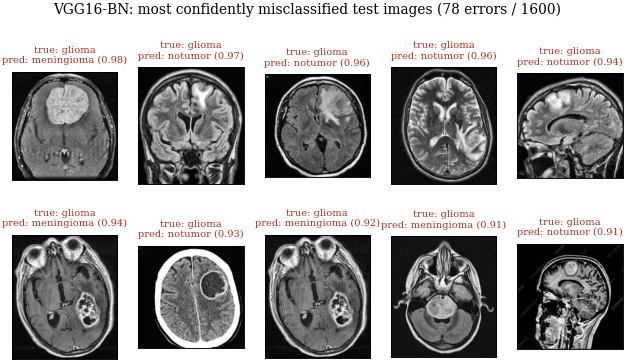

In [47]:
# ── F12: misclassified exemplars (reference model) ─────────────────────────
r_ref  = all_results[REFERENCE]
wrong  = np.where(r_ref["preds"] != r_ref["true"])[0]
paths  = [p for p, _ in tta_dataset.samples]

if len(wrong) == 0:
    print("No misclassifications on the held-out test set - skipping F12.")
else:
    conf_w = r_ref["probs"][wrong].max(1)
    order  = wrong[np.argsort(-conf_w)]          # most confidently wrong first
    show   = order[:min(10, len(order))]

    ncol = 5
    nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.16, 1.85 * nrow))
    for ax, idx in zip(np.atleast_1d(axes).flat, show):
        ax.imshow(Image.open(paths[idx]).convert("L"), cmap="gray")
        t, p = class_names[r_ref["true"][idx]], class_names[r_ref["preds"][idx]]
        c = r_ref["probs"][idx].max()
        ax.set_title(f"true: {t}\npred: {p} ({c:.2f})", fontsize=6.5, color="#AA3322")
        ax.set_xticks([]); ax.set_yticks([])
    for ax in np.atleast_1d(axes).flat[len(show):]:
        ax.axis("off")
    fig.suptitle(f"{REFERENCE}: most confidently misclassified test images "
                 f"({len(wrong)} errors / {len(r_ref['true'])})", y=1.01, fontsize=9)
    save_fig(fig, "f12_misclassified_examples")

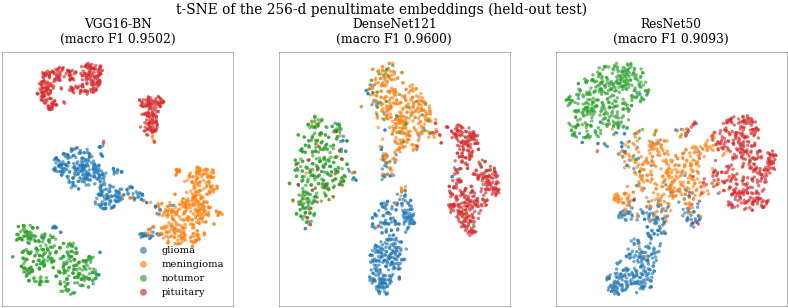

In [48]:
# ── F13: t-SNE of the 256-d penultimate embeddings ─────────────────────────
from sklearn.manifold import TSNE

have = [(n, r) for n, r in all_results.items() if r.get("features") is not None]
if not have:
    print("No cached embeddings - skipping F13.")
else:
    fig, axes = plt.subplots(1, len(have), figsize=(2.6 * len(have) + 1.4, 3.0),
                             squeeze=False)
    for j, (name, r) in enumerate(have):
        feats = r["features"]
        perp  = float(min(30, max(5, (len(feats) - 1) / 3)))
        emb = TSNE(n_components=2, perplexity=perp, init="pca",
                   random_state=RANDOM_SEED, max_iter=1000).fit_transform(feats)
        ax = axes[0, j]
        for i, c in enumerate(class_names):
            m = r["clean_true"] == i
            ax.scatter(emb[m, 0], emb[m, 1], s=5, alpha=0.65, label=c,
                       edgecolors="none")
        ax.set_title(f"{name}\n(macro F1 {r['metrics']['f1']:.4f})", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_alpha(0.3)
    axes[0, 0].legend(frameon=False, fontsize=6.5, markerscale=2, loc="best")
    fig.suptitle("t-SNE of the 256-d penultimate embeddings (held-out test)",
                 y=1.03, fontsize=9)
    save_fig(fig, "f13_tsne_embeddings")

## §13.9 Statistical summary

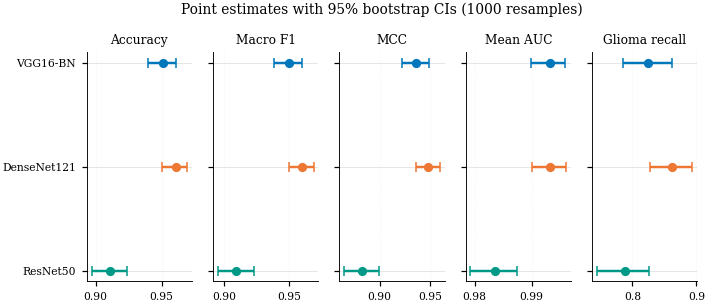

'/kaggle/working/figures/f14_bootstrap_forest'

In [49]:
# ── F14: bootstrap CI forest plot ──────────────────────────────────────────
metrics_to_plot = [("acc", "Accuracy"), ("f1", "Macro F1"), ("mcc", "MCC"),
                   ("auc", "Mean AUC"), ("glioma_recall", "Glioma recall")]
names = list(all_results.keys())

fig, axes = plt.subplots(1, len(metrics_to_plot),
                         figsize=(7.16, 2.7), sharey=True)
for ax, (mk, mlabel) in zip(axes, metrics_to_plot):
    for i, name in enumerate(names):
        ci = all_results[name]["ci"].get(mk)
        if ci is None:
            continue
        lo, hi = ci
        pt = all_results[name]["metrics"][CI_TO_METRIC[mk]]
        ax.errorbar(pt, i, xerr=[[pt - lo], [hi - pt]], fmt="o", ms=5,
                    color=mcol(name), ecolor=mcol(name),
                    elinewidth=1.6, capsize=3)
    ax.set_title(mlabel, fontsize=8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=7)
    ax.grid(axis="x", alpha=0.25, ls=":"); _despine(ax)
    ax.invert_yaxis()
fig.suptitle(f"Point estimates with 95% bootstrap CIs ({BOOTSTRAP_RUNS} resamples)",
             y=1.05, fontsize=9)
save_fig(fig, "f14_bootstrap_forest")

## §13.10 Literature comparison — scaffold

Fill `LITERATURE` in with the papers you cite. The rows for **this work** are inserted
automatically from the live results, so they can never disagree with your own tables.

Rows are pre-populated with commonly-cited entries on this dataset **as placeholders only** —
verify every one against the paper before submitting. Delete anything you have not personally
checked.

In [50]:
LITERATURE = [
    # {"Study": "Author et al. (2023)", "Method": "...", "Dataset": "...",
    #  "Accuracy": 0.00, "Macro F1": None, "Notes": "..."},
]

lit_rows = list(LITERATURE)
for name, r in all_results.items():
    m = r["metrics"]
    lit_rows.append({
        "Study": "**This work**",
        "Method": f"{name} + focal loss + TTA"
                  + (" + SWA" if SPEC_BY_KEY[r["key"]]["use_swa"] else ""),
        "Dataset": "Brain Tumor MRI (4-class, held-out Testing/)",
        "Accuracy": round(m["accuracy"], 4),
        "Macro F1": round(m["f1"], 4),
        "Notes": f"n={len(r['true'])}, TTA x{TTA_RUNS}, 95% CI reported",
    })
literature_df = pd.DataFrame(lit_rows)
print("T8 - Literature comparison (VERIFY every external row before citing)")
print(literature_df.to_string(index=False))
if not LITERATURE:
    print("\n[!] LITERATURE is empty - only this work's rows are present. "
          "Add your cited papers above.")

T8 - Literature comparison (VERIFY every external row before citing)
        Study                            Method                                      Dataset  Accuracy  Macro F1                           Notes
**This work** VGG16-BN + focal loss + TTA + SWA Brain Tumor MRI (4-class, held-out Testing/)    0.9513    0.9502 n=1600, TTA x5, 95% CI reported
**This work**    DenseNet121 + focal loss + TTA Brain Tumor MRI (4-class, held-out Testing/)    0.9606    0.9600 n=1600, TTA x5, 95% CI reported
**This work**       ResNet50 + focal loss + TTA Brain Tumor MRI (4-class, held-out Testing/)    0.9106    0.9093 n=1600, TTA x5, 95% CI reported

[!] LITERATURE is empty - only this work's rows are present. Add your cited papers above.


## §13.11 Export the whole pack

In [51]:
thesis_tables = {
    "t1_dataset_composition": dataset_df,
    "t2_hyperparameters":     hyperparams_df,
    "t3_augmentation":        aug_df,
    "t4_complexity":          complexity_df,
    "t5_per_class_metrics":   per_class_df,
    "t6_generalisation_gap":  gap_df,
    "t7_calibration":         calibration_df,
    "t8_literature":          literature_df,
}
export_tables(thesis_tables)

print("\n" + "=" * 72)
print("THESIS / CONFERENCE PACK")
print("=" * 72)
figs = sorted(f for f in os.listdir(FIG_DIR) if f.endswith(".pdf"))
tabs = sorted(f for f in os.listdir(TAB_DIR) if f.endswith(".tex"))
print(f"\nFigures ({len(figs)}), each as .png @300dpi + .pdf (vector, for LaTeX):")
for f in figs:
    print(f"   figures/{f[:-4]}.{{png,pdf}}")
print(f"\nTables ({len(tabs)}), each as .csv + .md + .tex:")
for t in tabs:
    print(f"   tables/{t[:-4]}.{{csv,md,tex}}")

with open(os.path.join(TAB_DIR, "temperatures.json"), "w") as f:
    json.dump(temps, f, indent=2)
print("\n   tables/temperatures.json   (fitted temperature per model)")

  t1_dataset_composition: csv + md + tex
  t2_hyperparameters: csv + md + tex
  t3_augmentation: csv + md + tex
  t4_complexity: csv + md + tex
  t5_per_class_metrics: csv + md + tex
  t6_generalisation_gap: csv + md + tex
  t7_calibration: csv + md + tex
  t8_literature: csv + md + tex

THESIS / CONFERENCE PACK

Figures (26), each as .png @300dpi + .pdf (vector, for LaTeX):
   figures/calibration_comparison.{png,pdf}
   figures/calibration_densenet121.{png,pdf}
   figures/calibration_resnet50.{png,pdf}
   figures/calibration_vgg16.{png,pdf}
   figures/confusion_matrices.{png,pdf}
   figures/f10_temperature_scaling.{png,pdf}
   figures/f11_confidence_correct_vs_wrong.{png,pdf}
   figures/f12_misclassified_examples.{png,pdf}
   figures/f13_tsne_embeddings.{png,pdf}
   figures/f14_bootstrap_forest.{png,pdf}
   figures/f15_accuracy_vs_cost.{png,pdf}
   figures/f1_class_distribution.{png,pdf}
   figures/f2_class_samples.{png,pdf}
   figures/f3_preprocessing_pipeline.{png,pdf}
   figures/f4

## §12 Final cleanup

Everything the XAI notebook needs is on disk. Release the session.

**For the XAI notebook:** point `MODEL_DIR` at this notebook's output and load
`models/best_overall_model.pth` (or any of `vgg16_best.pth` / `densenet121_best.pth` /
`resnet50_best.pth`). Each checkpoint is self-describing — read `backbone_name`, `in_features`,
`num_classes`, `class_names` and `img_size` from the dict; hard-code nothing.

In [52]:
free_gpu("all_results", "histories", "criterion", "class_weights",
         "train_loader", "val_loader", "bn_loader")

try:
    import psutil
    print(f"Process RSS: {psutil.Process().memory_info().rss / 1e9:.2f} GB")
except ImportError:
    pass

print("\nNotebook complete.")
print(f"Checkpoints for the XAI notebook: {MODEL_DIR}")

  GPU 0: allocated 0.03 GB | reserved 0.46 GB
  GPU 1: allocated 0.02 GB | reserved 0.23 GB
Process RSS: 23.12 GB

Notebook complete.
Checkpoints for the XAI notebook: /kaggle/working/models
